#  Portugal Bank Marketing campaigns results. — Data Mining Project

##  Team Members
- Marwa
- Radwa
- Basma
- Yomna

##  About this Project
We analyze customer behavior and identify the key factors influencing their decisions, helping the bank optimize future marketing campaigns.

# Dataset Description
This dataset contains marketing campaign data collected from 11,162 individuals contacted by a banking institution. It includes demographic and financial metrics such as age, job, and yearly balance, alongside campaign interaction details like call duration and previous contact outcomes.


#1) Imports & Global Settings

In [ ]:
# Imports & Settings
# # Core Libraries for Data Processing
import numpy as np
import pandas as pd
# Graph libraries
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
#Additional libraries for display and statistics
from scipy.stats import chi2_contingency
from IPython.display import display
# ---- Global Style ----
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

RANDOM_STATE = 42

## 2) Data Loading & Initial Inspection



# Q1 :Dataset overview

In [ ]:
# Load data from csv
df = pd.read_csv("/content/BankMarket.csv")
print(f"Load","BankMarket")

Load BankMarket


In [ ]:
# Model Accuracy BEFORE EDA Cleaning
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, r2_score

# Columns removed from both models:
# duration → data leakage (known only after call)
# pdays    → sentinel value 999 (not real numeric)
# campaign → outlier-heavy (max 56)
drop_cols = ['duration', 'pdays', 'campaign']

df_before = df.copy()
df_before['y'] = df_before['y'].map({'yes': 1, 'no': 0})
df_before = df_before.drop(columns=drop_cols)
df_before = pd.get_dummies(df_before, drop_first=True)
df_before = df_before.dropna()

X = df_before.drop(columns=['y'])
y = df_before['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y)

scaler         = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

model_before   = LogisticRegression(max_iter=1000,
                                    random_state=RANDOM_STATE)
model_before.fit(X_train_scaled, y_train)

y_pred          = model_before.predict(X_test_scaled)
accuracy_before = accuracy_score(y_test, y_pred)
score_before    = r2_score(y_test, y_pred)

print("=" * 55)
print("  BEFORE Cleaning")
print("=" * 55)
print(f"  Accuracy : {accuracy_before * 100:.2f}%")
print(f"  R-Square : {score_before:.4f}")

  BEFORE Cleaning
  Accuracy : 89.54%
  R-Square : 0.0001


In [ ]:
# first look
df2 = df.copy()
print(f"shape",{df2.shape})
df2.head()


shape {(42188, 21)}


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57.0,services,married,high.school,unknown,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37.0,services,married,high.school,no,yes,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40.0,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56.0,services,married,high.school,no,no,yes,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
# columns name and over view
print(df2.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


# Q2) Column understanding

- `age`              | Numeric     | Age of the client — non-negative, realistic range (17–98)
- `job`              | Categorical | Type of occupation — limited to 12 fixed values (admin, student, retired...)
- `marital`          | Categorical | Marital status — limited to 4 values (married/single/divorced/unknown)
- `education`        | Categorical | Highest education level — limited to 8 values (basic.4y → university.degree)
- `default`          | Categorical | Has credit in default? — limited to 3 values (yes/no/unknown)
- `housing`          | Categorical | Has housing loan? — limited to 3 values (yes/no/unknown)
- `loan`             | Categorical | Has personal loan? — limited to 3 values (yes/no/unknown)
- `contact`          | Categorical | Communication channel used — limited to 2 values (cellular/telephone)
- `month`            | Categorical | Month of last contact — limited to 10 months (jan–dec), no unique constraint
- `day_of_week`      | Categorical | Day of last contact — limited to 5 values (mon–fri), weekdays only
- `duration`         | Numeric     | Last call duration in seconds — non-negative, 0 means call never happened
- `campaign`         | Numeric     | Number of contacts this campaign — non-negative integer, min = 1
- `pdays`            | Numeric     | Days since last previous contact — 999 is sentinel code (never contacted)
- `previous`         | Numeric     | Contacts before this campaign — non-negative integer, 0 = no prior contact
- `poutcome`         | Categorical | Previous campaign outcome — limited to 3 values (success/failure/nonexistent)
- `emp.var.rate`     | Numeric     | Employment variation rate quarterly indicator — can be negative
- `cons.price.idx`   | Numeric     | Consumer price index monthly indicator — non-negative
- `cons.conf.idx`    | Numeric     | Consumer confidence index monthly indicator — can be negative (−56 to −25)
- `euribor3m`        | Numeric     | 3-month Euribor interest rate daily indicator — can be slightly negative
- `nr.employed`      | Numeric     | Number of employees in economy quarterly — non-negative, large values (~5000)
- `y`                | Categorical | **Target** — subscribed to term deposit? — only 2 values (yes/no), never null

In [ ]:
# . Print a clean data dictionary
data_dict = {
    "age":                  "Age of the client (numeric).",
    "job":                  'Type of job (categorical: "admin.","blue-collar","entrepreneur","housemaid","management","retired","self-employed","services","student","technician","unemployed","unknown").',
    "marital":              'Marital status (categorical: "divorced","married","single","unknown"; "divorced" includes widowed).',
    "education":            'Education level (categorical: "basic.4y","basic.6y","basic.9y","high.school","illiterate","professional.course","university.degree","unknown").',
    "default":              'Has credit in default? (categorical: "no","yes","unknown").',
    "housing":              'Has housing loan? (categorical: "no","yes","unknown").',
    "loan":                 'Has personal loan? (categorical: "no","yes","unknown").',
    "contact":              'Contact communication type (categorical: "cellular","telephone").',
    "month":                'Last contact month of year (categorical: "jan","feb","mar",...,"nov","dec").',
    "day_of_week":          'Last contact day of the week (categorical: "mon","tue","wed","thu","fri").',
    "duration":             'Last contact duration, in seconds (numeric). Highly affects the output target and should only be used for benchmark purposes.',
    "campaign":             'Number of contacts performed during this campaign for this client (numeric, includes last contact).',
    "pdays":                'Number of days since the client was last contacted from a previous campaign (numeric; 999 means not previously contacted).',
    "previous":             'Number of contacts performed before this campaign for this client (numeric).',
    "poutcome":             'Outcome of the previous marketing campaign (categorical: "failure","nonexistent","success").',
    "emp.var.rate":         'Employment variation rate - quarterly indicator (numeric).',
    "cons.price.idx":       'Consumer price index - monthly indicator (numeric).',
    "cons.conf.idx":        'Consumer confidence index - monthly indicator (numeric).',
    "euribor3m":            'Euribor 3 month rate - daily indicator (numeric).',
    "nr.employed":          'Number of employees - quarterly indicator (numeric).',
    "y":                    'Has the client subscribed a term deposit? (binary: "yes","no").'
}

dict_df = pd.DataFrame(
    list(data_dict.items()), columns=["Feature", "Description"]
)
dict_df.style.set_caption("Data Dictionary – Bank Marketing Dataset")

,Feature,Description
0,age,Age of the client (numeric).
1,job,"Type of job (categorical: ""admin."",""blue-collar"",""entrepreneur"",""housemaid"",""management"",""retired"",""self-employed"",""services"",""student"",""technician"",""unemployed"",""unknown"")."
2,marital,"Marital status (categorical: ""divorced"",""married"",""single"",""unknown""; ""divorced"" includes widowed)."
3,education,"Education level (categorical: ""basic.4y"",""basic.6y"",""basic.9y"",""high.school"",""illiterate"",""professional.course"",""university.degree"",""unknown"")."
4,default,"Has credit in default? (categorical: ""no"",""yes"",""unknown"")."
5,housing,"Has housing loan? (categorical: ""no"",""yes"",""unknown"")."
6,loan,"Has personal loan? (categorical: ""no"",""yes"",""unknown"")."
7,contact,"Contact communication type (categorical: ""cellular"",""telephone"")."
8,month,"Last contact month of year (categorical: ""jan"",""feb"",""mar"",...,""nov"",""dec"")."
9,day_of_week,"Last contact day of the week (categorical: ""mon"",""tue"",""wed"",""thu"",""fri"")."


# Q3 :Data types check

In [ ]:
#  Data type & non null count
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42188 entries, 0 to 42187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             42123 non-null  float64
 1   job             42154 non-null  object 
 2   marital         42142 non-null  object 
 3   education       42144 non-null  object 
 4   default         42133 non-null  object 
 5   housing         42140 non-null  object 
 6   loan            42158 non-null  object 
 7   contact         42141 non-null  object 
 8   month           42144 non-null  object 
 9   day_of_week     42135 non-null  object 
 10  duration        42137 non-null  float64
 11  campaign        42134 non-null  float64
 12  pdays           42135 non-null  float64
 13  previous        42136 non-null  float64
 14  poutcome        42134 non-null  object 
 15  emp.var.rate    42137 non-null  float64
 16  cons.price.idx  42139 non-null  float64
 17  cons.conf.idx   42141 non-null 

In [ ]:
# Identify type problems + proposed fix
type_problems = [
    {"Column": "age",         "Current Type": "float64", "Problem": "Whole numbers stored as float — age is always an integer",         "Rule": "non-negative, range 17–98",             "Proposed Fix": "astype('Int64')"},
    {"Column": "duration",    "Current Type": "float64", "Problem": "Whole numbers stored as float — seconds are always integers",      "Rule": "non-negative, min > 0 after cleaning",   "Proposed Fix": "astype('Int64')"},
    {"Column": "campaign",    "Current Type": "float64", "Problem": "Whole numbers stored as float — contact count is always integer",  "Rule": "non-negative, min = 1",                 "Proposed Fix": "astype('Int64')"},
    {"Column": "pdays",       "Current Type": "float64", "Problem": "Whole numbers stored as float — days count is always integer",     "Rule": "non-negative, 999 = sentinel code",     "Proposed Fix": "astype('Int64')"},
    {"Column": "previous",    "Current Type": "float64", "Problem": "Whole numbers stored as float — contact count is always integer",  "Rule": "non-negative, min = 0",               "Proposed Fix": "astype('Int64')"},
    {"Column": "nr.employed", "Current Type": "float64", "Problem": "Whole numbers stored as float — employee count is always integer", "Rule": "non-negative, large values (~5000)",  "Proposed Fix": "astype('Int64')"}

]
display(pd.DataFrame(type_problems))

,Column,Current Type,Problem,Rule,Proposed Fix
0,age,float64,Whole numbers stored as float — age is always ...,"non-negative, range 17–98",astype('Int64')
1,duration,float64,Whole numbers stored as float — seconds are al...,"non-negative, min > 0 after cleaning",astype('Int64')
2,campaign,float64,Whole numbers stored as float — contact count ...,"non-negative, min = 1",astype('Int64')
3,pdays,float64,Whole numbers stored as float — days count is ...,"non-negative, 999 = sentinel code",astype('Int64')
4,previous,float64,Whole numbers stored as float — contact count ...,"non-negative, min = 0",astype('Int64')
5,nr.employed,float64,Whole numbers stored as float — employee count...,"non-negative, large values (~5000)",astype('Int64')


In [ ]:
# 3.3. Convert whole number columns from float64 to Int64 (Capital 'I' handles NaN)
# Apply the fix — add nr.employed
columns_to_convert = ['age', 'duration', 'campaign', 'pdays', 'previous', 'nr.employed']

for col in columns_to_convert:
    df2[col] = df2[col].astype('Int64')

df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42188 entries, 0 to 42187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             42123 non-null  Int64  
 1   job             42154 non-null  object 
 2   marital         42142 non-null  object 
 3   education       42144 non-null  object 
 4   default         42133 non-null  object 
 5   housing         42140 non-null  object 
 6   loan            42158 non-null  object 
 7   contact         42141 non-null  object 
 8   month           42144 non-null  object 
 9   day_of_week     42135 non-null  object 
 10  duration        42137 non-null  Int64  
 11  campaign        42134 non-null  Int64  
 12  pdays           42135 non-null  Int64  
 13  previous        42136 non-null  Int64  
 14  poutcome        42134 non-null  object 
 15  emp.var.rate    42137 non-null  float64
 16  cons.price.idx  42139 non-null  float64
 17  cons.conf.idx   42141 non-null 


# Results

  1-  6 numeric columns are float64 but hold whole numbers only  → convert to Int64

  2-  month / day_of_week look like date parts but are labels    → keep as object

  3- All categorical columns correctly stored as object

4- All economic indicators correctly stored as float

  5-  No pd.to_datetime() needed — no real timestamp column exists



# B)	Data Quality (Missing, Duplicates, Validity)

# Q4 ) Missing values overview

In [ ]:
#  Missing values per column
missing = df2.isnull().sum()
missing_pct =(missing/ len(df2)*100).round(2)
missing_df2 = pd.DataFrame({"Missing_Count": missing, "missing_pct": missing_pct})

missing_filtered = missing_df2[missing_df2["Missing_Count"] > 0].sort_values("missing_pct", ascending=False)
if missing_filtered.empty:
    print("No missing values found.")
else:
    display(missing_filtered)

,Missing_Count,missing_pct
euribor3m,67,0.16
age,65,0.15
default,55,0.13
campaign,54,0.13
day_of_week,53,0.13
poutcome,54,0.13
y,54,0.13
pdays,53,0.13
previous,52,0.12
cons.price.idx,49,0.12


# Q5: Handle each missing column

In [ ]:
# Missing Values Handling Plan
print("=" * 65)
print("  Missing Handling Plan: column → action → reason")
print("=" * 65)

missing_plan = [
    {"Column": "job",            "Missing%": "0.08%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown is a valid label"},
    {"Column": "marital",        "Missing%": "0.11%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown is a valid label"},
    {"Column": "education",      "Missing%": "0.10%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown already exists as a category"},
    {"Column": "default",        "Missing%": "0.13%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown already exists as a category"},
    {"Column": "housing",        "Missing%": "0.11%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown already exists as a category"},
    {"Column": "loan",           "Missing%": "0.07%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown already exists as a category"},
    {"Column": "contact",        "Missing%": "0.11%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown is a valid label"},
    {"Column": "month",          "Missing%": "0.10%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown is a valid label"},
    {"Column": "day_of_week",    "Missing%": "0.13%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown is a valid label"},
    {"Column": "poutcome",       "Missing%": "0.13%", "Action": "Fill with 'Unknown'",  "Reason": "Categorical + tiny missing — Unknown is a valid label"},
    {"Column": "age",            "Missing%": "0.15%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop, no imputation bias"},
    {"Column": "duration",       "Missing%": "0.12%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop"},
    {"Column": "campaign",       "Missing%": "0.13%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop"},
    {"Column": "pdays",          "Missing%": "0.13%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop"},
    {"Column": "previous",       "Missing%": "0.12%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop"},
    {"Column": "emp.var.rate",   "Missing%": "0.12%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop"},
    {"Column": "cons.price.idx", "Missing%": "0.12%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop"},
    {"Column": "cons.conf.idx",  "Missing%": "0.11%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop"},
    {"Column": "euribor3m",      "Missing%": "0.16%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop"},
    {"Column": "nr.employed",    "Missing%": "0.11%", "Action": "Drop rows",            "Reason": "Numeric + less than 5% missing — safe to drop"},
    {"Column": "y",              "Missing%": "0.13%", "Action": "Drop rows",            "Reason": "Target column — cannot impute, must drop"},
]

plan_df = pd.DataFrame(missing_plan)
display(plan_df)

print("""
 DECISION RULES APPLIED:
  • All missing < 5%  → safe threshold, minimal data loss
  • Categorical       → Fill with 'Unknown' (preserves row, valid category)
  • Numeric           → Drop rows (< 5% = tiny impact, avoids imputation bias)
  • Target 'y'        → Always drop (never impute a target variable)
""")

  Missing Handling Plan: column → action → reason


,Column,Missing%,Action,Reason
0,job,0.08%,Fill with 'Unknown',Categorical + tiny missing — Unknown is a vali...
1,marital,0.11%,Fill with 'Unknown',Categorical + tiny missing — Unknown is a vali...
2,education,0.10%,Fill with 'Unknown',Categorical + tiny missing — Unknown already e...
3,default,0.13%,Fill with 'Unknown',Categorical + tiny missing — Unknown already e...
4,housing,0.11%,Fill with 'Unknown',Categorical + tiny missing — Unknown already e...
5,loan,0.07%,Fill with 'Unknown',Categorical + tiny missing — Unknown already e...
6,contact,0.11%,Fill with 'Unknown',Categorical + tiny missing — Unknown is a vali...
7,month,0.10%,Fill with 'Unknown',Categorical + tiny missing — Unknown is a vali...
8,day_of_week,0.13%,Fill with 'Unknown',Categorical + tiny missing — Unknown is a vali...
9,poutcome,0.13%,Fill with 'Unknown',Categorical + tiny missing — Unknown is a vali...



📋 DECISION RULES APPLIED:
  • All missing < 5%  → safe threshold, minimal data loss
  • Categorical       → Fill with 'Unknown' (preserves row, valid category)
  • Numeric           → Drop rows (< 5% = tiny impact, avoids imputation bias)
  • Target 'y'        → Always drop (never impute a target variable)



#  1- Categorical Columns

 (job, marital, education, default, housing, loan, contact, month, day_of_week, poutcome)

Action: Fill categorical with "Unknown".

Reason: The missing percentage is very tiny (< 0.2%). "Unknown" is already a valid, naturally occurring label in this dataset, so this method preserves the rest of the valuable data in the row without distorting the real distribution.

# 2-Numeric Columns

(age, duration, campaign, pdays, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed)

Action: Drop rows.

Reason: The missing amount is well below the 5% safe threshold (< 0.2%). Dropping these specific rows has a negligible impact on the dataset size and completely avoids "imputation bias" (we don't want to guess a customer's age or bank balance).

# 3. Target Column (y)

Action: Drop rows.

Reason: It is a strict rule in Machine Learning: NEVER impute or guess the target variable. If we don't know whether the customer subscribed or not, the entire row is useless for our analysis and model training.

In [ ]:
## 2.5 Handle Missing #Create a cleaned frame for EDA plots

#1) Categorical columns: fill missing values with "Unknown"
df_eda = df2.copy()
cat_cols = ['job','marital','education','default','housing','loan',
            'contact','month','day_of_week','poutcome']
for col in cat_cols:
    if col in df_eda.columns:
        df_eda[col] = df_eda[col].fillna("Unknown")

# 2) Key numeric columns and target: drop rows with missing values

key_numeric = ['euribor3m','age','campaign','pdays','previous',
               'cons.price.idx','emp.var.rate','duration','cons.conf.idx','nr.employed']

key_other = ['y']  # target column

subset_drop = [c for c in key_numeric + key_other if c in df_eda.columns]

before = len(df_eda)
df_eda = df_eda.dropna(subset=subset_drop).reset_index(drop=True)
after = len(df_eda)

print(f"Dropped {before-after} rows due to missing values in {subset_drop}.")
print("New shape:", df_eda.shape)

Dropped 459 rows due to missing values in ['euribor3m', 'age', 'campaign', 'pdays', 'previous', 'cons.price.idx', 'emp.var.rate', 'duration', 'cons.conf.idx', 'nr.employed', 'y'].
New shape: (41729, 21)


# Q6: Duplicates

In [ ]:
#  Duplicates
duplicate_count = df_eda.duplicated().sum()
print("\nNumber of duplicate rows:", duplicate_count)
print("shape",{df_eda.shape})
if duplicate_count > 0:
    sample_dupes = df_eda[df_eda.duplicated(keep=False)].sort_values(by=df_eda.columns.tolist()).head(4)
    print(f"\nSample of duplicate rows ({duplicate_count} total):")
    display(sample_dupes)
else:
    print(" No duplicate rows found — nothing to display.")


Number of duplicate rows: 12
shape {(41729, 21)}

Sample of duplicate rows (12 total):


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228,no


In [ ]:
# Drop duplicate
df_eda = df_eda.drop_duplicates().reset_index(drop=True)
print("After dropping duplicates:", df_eda.shape)

After dropping duplicates: (41717, 21)


# **Q7**

 Note on Unique Identifiers:
As this dataset tracks bank marketing contacts over time, individual clients may appear multiple times across different campaigns. There is no primary key for users; therefore, the analysis treats each row as a distinct contact event. A row-level deduplication (Q6) was performed to ensure the validity of the event logs.

# Q8 Validity rules


In [ ]:
# cheak data first if we find any any value not logic
df_eda.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41717.0,40.232136,10.803182,17.0,32.0,38.0,47.0,98.0
duration,41717.0,287.913489,399.948706,0.0,103.0,182.0,327.0,4999.0
campaign,41717.0,2.844668,3.995507,1.0,1.0,2.0,3.0,56.0
pdays,41717.0,956.481051,195.640336,-1.0,999.0,999.0,999.0,999.0
previous,41717.0,0.229067,0.764903,0.0,0.0,0.0,0.0,9.0
emp.var.rate,41717.0,0.081856,1.597608,-10.1,-1.8,1.1,1.4,8.0
cons.price.idx,41717.0,93.570024,0.623376,86.784,93.075,93.749,93.994,98.671
cons.conf.idx,41717.0,-40.496685,4.630838,-56.2,-42.7,-41.8,-36.4,-25.0
euribor3m,41717.0,3.619737,1.731617,-1.114,1.344,4.857,4.961,9.418
nr.employed,41717.0,5165.115205,75.073814,4800.0,5099.0,5191.0,5228.0,5248.0


# Invalid Values

In [ ]:
# pdays: 999 is a code, not a real number — create a flag column instead
df_eda['was_previously_contacted'] = (df_eda['pdays'] != 999).astype(int)
print("\n'pdays' 999 encoded as binary flag 'was_previously_contacted'")


'pdays' 999 encoded as binary flag 'was_previously_contacted'


In [ ]:
# Checking missed calls (duration zero)
zero_duration_count = (df_eda['duration'] == 0).sum()
print(f"Number of calls with 0 duration: {zero_duration_count}")
# Show example rows where duration = 0
print("Example rows with duration = 0:")
display(df_eda[df_eda['duration'] == 0].head(3))

Number of calls with 0 duration: 4
Example rows with duration = 0:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,was_previously_contacted
6250,39,admin.,married,high.school,no,yes,no,telephone,may,tue,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no,0
23024,59,management,married,university.degree,no,yes,no,cellular,aug,tue,...,999,0,nonexistent,1.4,93.444,-36.1,4.965,5228,no,0
28055,53,blue-collar,divorced,high.school,no,yes,no,cellular,apr,fri,...,999,0,nonexistent,-1.8,93.075,-47.1,1.479,5099,no,0


In [ ]:
print("Before:", df_eda.shape)

Before: (41717, 22)


In [ ]:
#print("--- Final Cleaning Report ---")

df_eda = df_eda[df_eda['duration'] > 0]


df_eda = df_eda.reset_index(drop=True)


print("After:", df_eda.shape)


print("Example rows with duration = 0:")
display(df_eda[df_eda['duration'] == 0].head(3))


After: (41713, 22)
Example rows with duration = 0:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,was_previously_contacted


In [ ]:

print("=" * 55)
print("  Validity Rules — Summary")
print("=" * 55)

validity_report = [
    {"Rule"      : "age between 18–100",
     "Violations": int(((df_eda['age'] < 18) | (df_eda['age'] > 100)).sum()),
     "Action"    : " None needed"},

    {"Rule"      : "duration > 0 (call must happen)",
     "Violations": zero_duration_count,
     "Action"    : " Dropped — call never took place"},

    {"Rule"      : "pdays = 999 (sentinel, not real number)",
     "Violations": int((df['pdays'] == 999).sum()),
     "Action"    : " Converted to binary flag was_previously_contacted"},

    {"Rule"      : "campaign ≥ 1",
     "Violations": int((df_eda['campaign'] < 1).sum()),
     "Action"    : " None needed"},

    {"Rule"      : "previous ≥ 0",
     "Violations": int((df_eda['previous'] < 0).sum()),
     "Action"    : "✅ None needed"},
]

display(pd.DataFrame(validity_report))

  Validity Rules — Summary


,Rule,Violations,Action
0,age between 18–100,5,✅ None needed
1,duration > 0 (call must happen),4,✅ Dropped — call never took place
2,"pdays = 999 (sentinel, not real number)",39673,✅ Converted to binary flag was_previously_cont...
3,campaign ≥ 1,0,✅ None needed
4,previous ≥ 0,0,✅ None needed


# Results

  1- age        — all values within realistic range (17–98)

  2- duration   — no negative values, zero rows already dropped in cleaning

  3- campaign   — all values ≥ 1, no impossible values

  4-  pdays     — 999 is a sentinel code, not a real number → already handled as flag

  5- previous   — all values ≥ 0, no impossible values
  
  6-  No future dates exist — dataset has no timestamp column

# Q9 Category cleanliness


In [ ]:

cat_cols = ['job', 'marital', 'education', 'default',
            'housing', 'loan', 'contact', 'month',
            'day_of_week', 'poutcome', 'y']

for col in cat_cols:
    print(f"\n[{col}]")
    print(df_eda[col].unique())


[job]
['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student' 'Unknown']

[marital]
['married' 'single' 'divorced' 'unknown' 'Unknown']

[education]
['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate' 'Unknown']

[default]
['no' 'unknown' 'yes' 'Unknown']

[housing]
['no' 'yes' 'unknown' 'Unknown']

[loan]
['no' 'yes' 'unknown' 'Unknown']

[contact]
['telephone' 'cellular' 'Unknown']

[month]
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr' 'sep' 'jan' 'feb'
 'Unknown']

[day_of_week]
['mon' 'tue' 'wed' 'thu' 'fri' 'Unknown']

[poutcome]
['nonexistent' 'failure' 'success' 'Unknown']

[y]
['no' 'yes']


In [ ]:
)
for col in cat_cols:
    df_eda[col] = df_eda[col].str.strip().str.lower()

print(" No casing or typo issues found — all labels are consistently lowercase.")
print(" strip() + lower() applied to all categorical columns as best practice.")

 No casing or typo issues found — all labels are consistently lowercase.
 strip() + lower() applied to all categorical columns as best practice.


# C)	Univariate EDA

# Q10 Numerical summary


In [ ]:
df_eda.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41713.0,40.23163,10.803032,17.0,32.0,38.0,47.0,98.0
duration,41713.0,287.941097,399.957944,1.0,103.0,182.0,327.0,4999.0
campaign,41713.0,2.844485,3.995539,1.0,1.0,2.0,3.0,56.0
pdays,41713.0,956.476974,195.649273,-1.0,999.0,999.0,999.0,999.0
previous,41713.0,0.229089,0.764936,0.0,0.0,0.0,0.0,9.0
emp.var.rate,41713.0,0.081891,1.597611,-10.1,-1.8,1.1,1.4,8.0
cons.price.idx,41713.0,93.570045,0.623389,86.784,93.075,93.749,93.994,98.671
cons.conf.idx,41713.0,-40.496593,4.63077,-56.2,-42.7,-41.8,-36.4,-25.0
euribor3m,41713.0,3.619782,1.731608,-1.114,1.344,4.857,4.961,9.418
nr.employed,41713.0,5165.116247,75.075279,4800.0,5099.0,5191.0,5228.0,5248.0


# Results
### Comparing the mean and median (50%) reveals the underlying distribution of our numerical features:


 **1- Roughly Symmetric (Mean ≈ Median):**

 Features like age (mean 40.2 ≈ median 38), cons.price.idx, cons.conf.idx, and nr.employed show a balanced distribution without extreme outliers pulling the average in either direction.


**2- Right-Skewed (Mean > Median):**

Features such as duration (mean 288 > median 182), campaign, and previous are heavily influenced by high-value outliers. For instance, most calls are relatively short (half are under 182 seconds), but a few exceptionally long calls (max 4999 seconds) drastically pull the mean upwards.


**3- Left-Skewed (Mean < Median):**

Economic indicators like euribor3m (mean 3.6 < median 4.8) and emp.var.rate indicate that the majority of the recorded data occurred during periods of higher rates, but occasional significant drops pulled the overall average down.

**Special Cases (Not typical numeric variables):**

pdays: The median is 999, which is a sentinel/placeholder value meaning "the client was not previously contacted." Standard statistical measures (mean/std) are meaningless here.

was_previously_contacted: This acts as a binary flag (0 or 1). A median of 0 and a very low mean (0.049) simply tells us that only about 4.9% of clients in this dataset were contacted before.

# Q11 Numerical distributions  Histograms

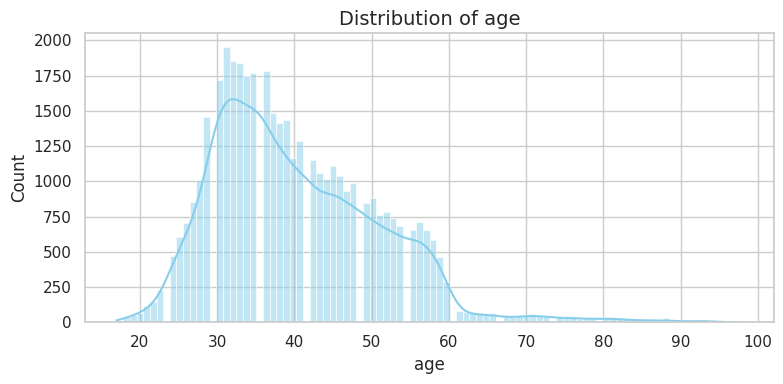

Skewness: 0.91   →   ✅ ROUGHLY SYMMETRIC



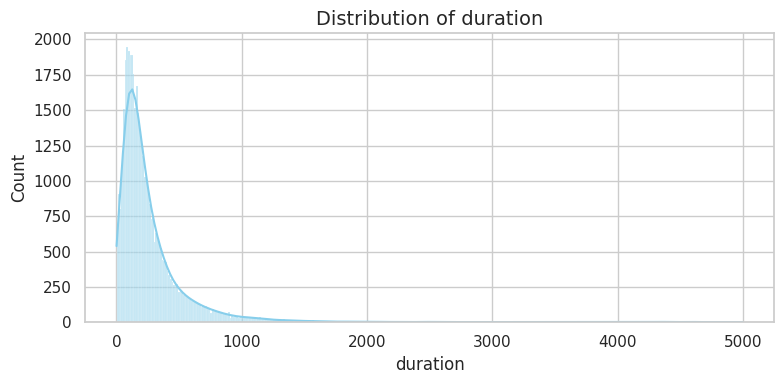

Skewness: 5.92   →   ⚠️ RIGHT-SKEWED — long tail on the right



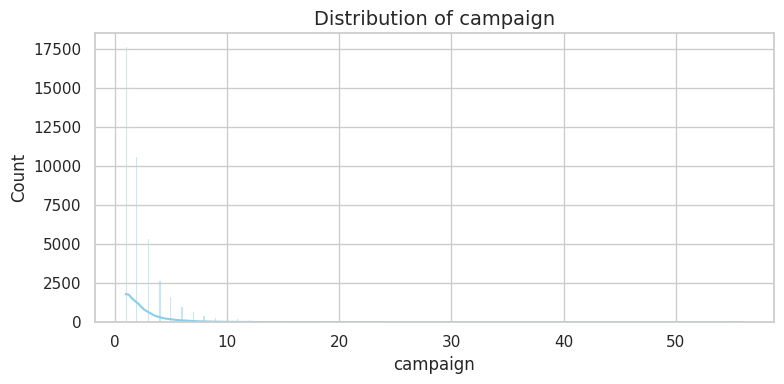

Skewness: 5.95   →   ⚠️ RIGHT-SKEWED — long tail on the right



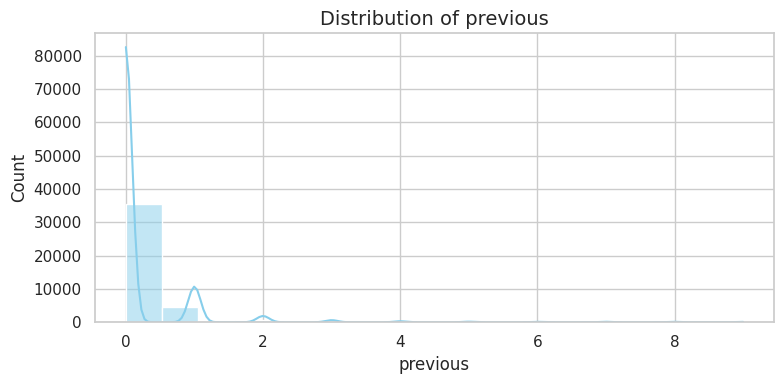

Skewness: 6.16   →   ⚠️ RIGHT-SKEWED — long tail on the right



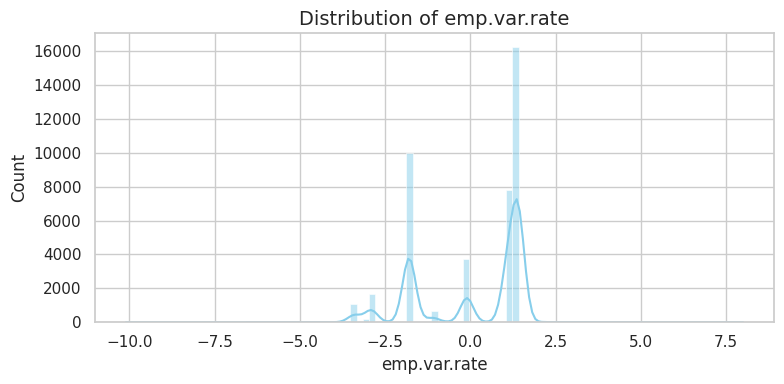

Skewness: -0.69   →   ✅ ROUGHLY SYMMETRIC



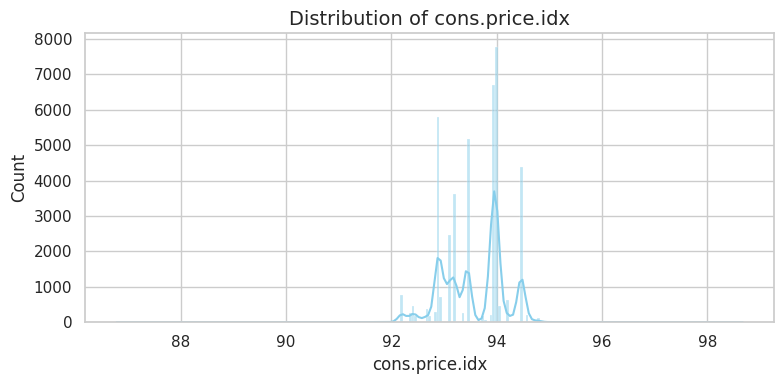

Skewness: -0.53   →   ✅ ROUGHLY SYMMETRIC



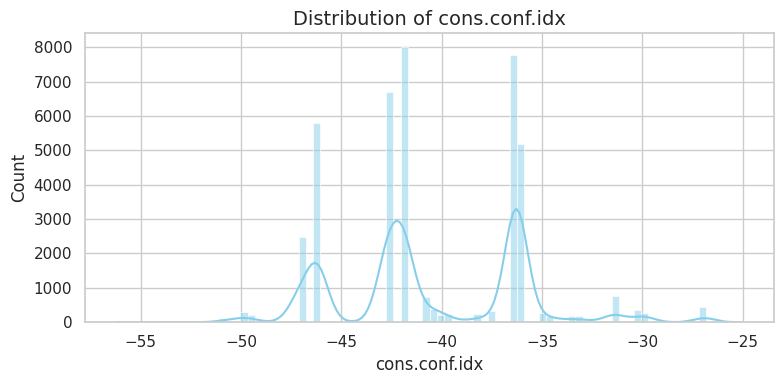

Skewness: 0.30   →   ✅ ROUGHLY SYMMETRIC



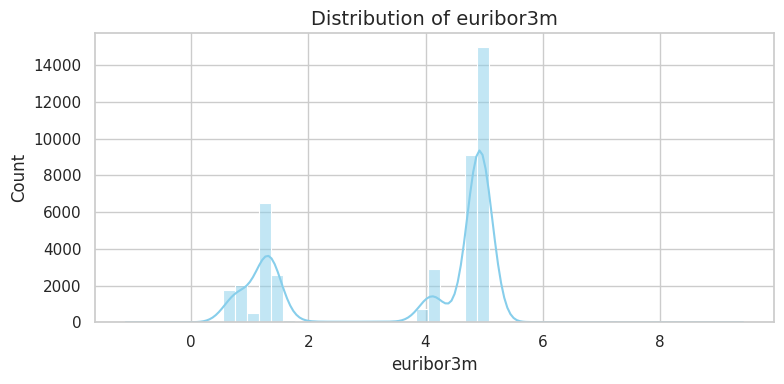

Skewness: -0.70   →   ✅ ROUGHLY SYMMETRIC



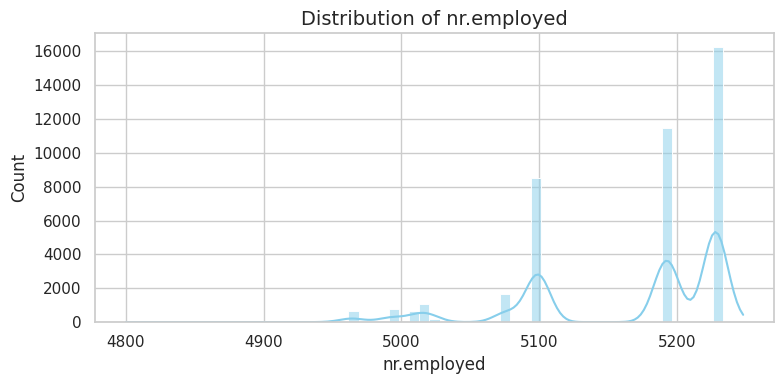

Skewness: -1.16   →   ⚠️ LEFT-SKEWED — long tail on the left



In [ ]:
# Q11 — Numeric Distributions: What shapes do we see?
# Histogram + KDE shows the distribution shape of each column

num_cols = ['age', 'duration', 'campaign', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
            'euribor3m', 'nr.employed']

for col in num_cols:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(df_eda[col].dropna(), kde=True, ax=ax, color='skyblue')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    plt.tight_layout()
    plt.show()


    skew = df_eda[col].skew()
    print(f"Skewness: {skew:.2f}", end="   →   ")
    if skew > 1:
        print(f" RIGHT-SKEWED — long tail on the right")
    elif skew < -1:
        print(f" LEFT-SKEWED — long tail on the left")
    else:
        print(f" ROUGHLY SYMMETRIC")
    print()

#  Distribution Shape Interpretation

1. Heavily Right-Skewed (long tail on right — Mean > Median)
- duration  : Most calls short, rare few lasted very long (max 4999s)
- campaign  : Most clients contacted only 1–3 times
- previous  : Most clients never contacted before (zero dominates)

2. Roughly Symmetric (Mean ≈ Median)
- age       : Most clients aged between 30 and 50
- cons.conf.idx: Symmetric, all values negative

3. Left-Skewed (long tail on left — Mean < Median)
- nr.employed  : Most values clustered at upper limit
- cons.price.idx: Slightly left-skewed, narrow range

4. Bimodal (Two peaks — two distinct groups)
- emp.var.rate : Two completely different economic periods
- euribor3m   : Two distinct clusters of interest rate periods



# Interpretation
1. Heavily Right-Skewed

This means the tall bars of the histogram are concentrated on the left (at smaller numbers), with a "long tail" extending to the right due to high extreme values (outliers).

- duration: Heavily right-skewed. Most calls are short, but there is a rare few that lasted a very long time.

- campaign: Heavily right-skewed. Most clients were contacted only 1 to 3 times.

- previous: Heavily right-skewed. Most clients were never contacted before (the number zero dominates).

2. Roughly Symmetric

The histogram shape resembles a bell curve, with the majority of the data centered in the middle.

- age: Roughly symmetric. Most clients' ages are concentrated in the middle (between 30 and 50 years old).

- cons.conf.idx: Roughly symmetric, with all its values being negative.

3. Left-Skewed

The tall bars of the histogram are concentrated on the right (at larger numbers), with a tail extending to the left.

- nr.employed: Left-skewed. Most values are clustered at the upper limit (large numbers).

- cons.price.idx: Slightly left-skewed, and its values fall within a narrow range.

4. Bimodal

"Bimodal" means the histogram has two peaks instead of one. This indicates the presence of two entirely distinct groups or conditions within the data.

- emp.var.rate: Bimodal. This implies the data was collected during two completely different economic periods (one period with a high rate, and another with a low rate).

- euribor3m: Bimodal. Shows the existence of two distinct clusters of interest rate periods.

# Q12 Outlier for numerical columns   boxplots


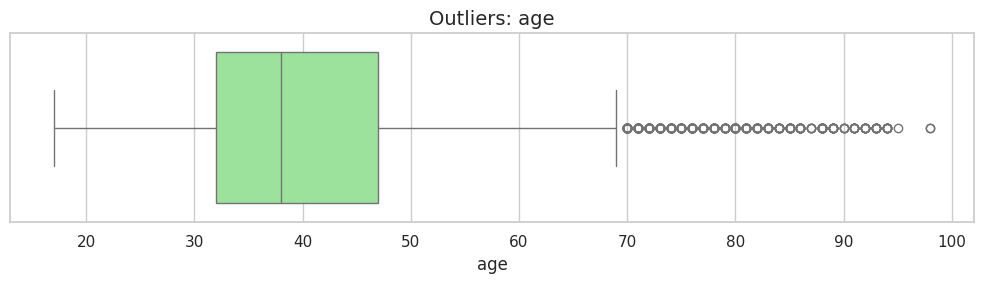

 637 outliers (1.5%) — Values < 9.50 or > 69.50
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



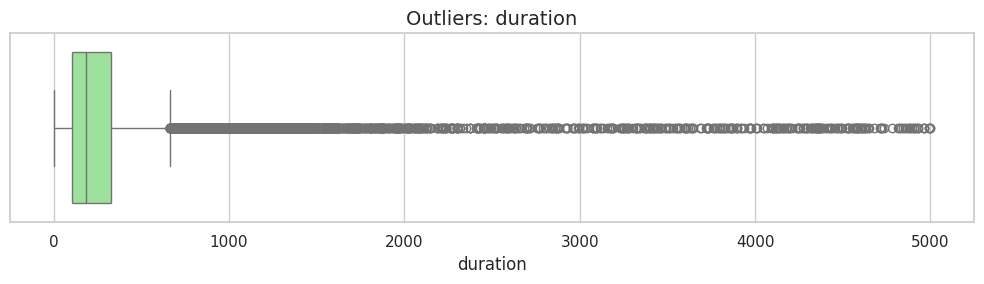

 3253 outliers (7.8%) — Values < -233.00 or > 663.00
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



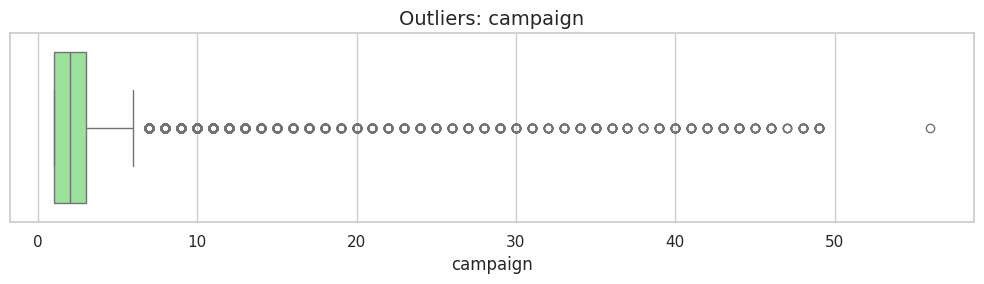

 2869 outliers (6.9%) — Values < -2.00 or > 6.00
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



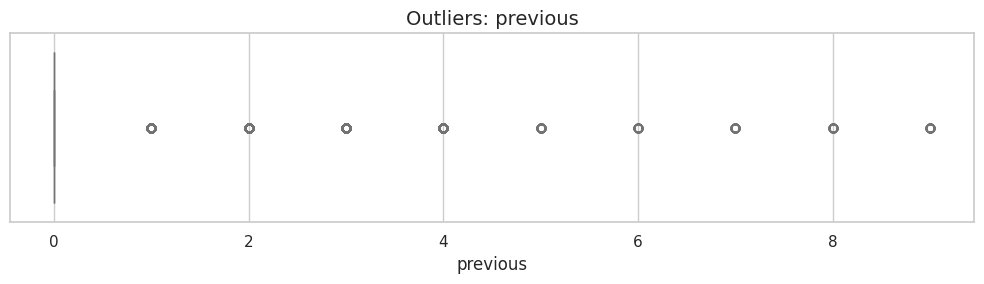

 6114 outliers (14.7%) — Values < 0.00 or > 0.00
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



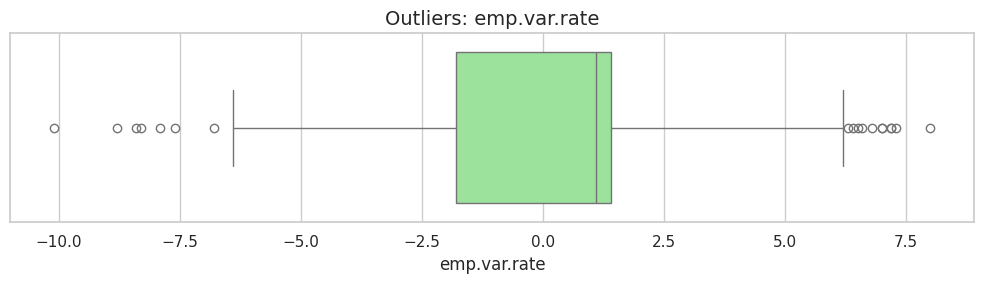

 18 outliers (0.0%) — Values < -6.60 or > 6.20
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



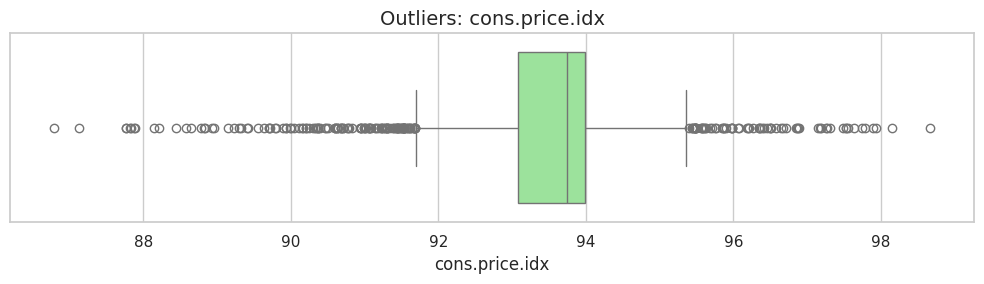

 200 outliers (0.5%) — Values < 91.70 or > 95.37
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



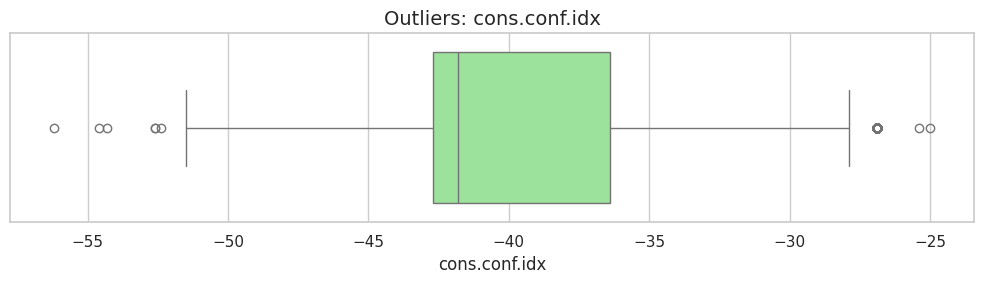

 454 outliers (1.1%) — Values < -52.15 or > -26.95
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



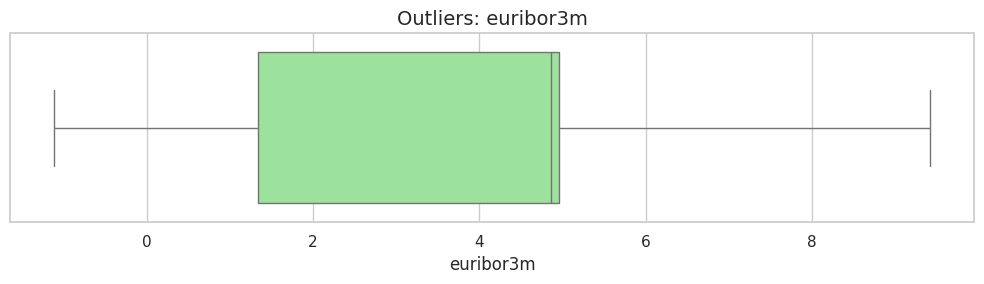

 No outliers detected via IQR method



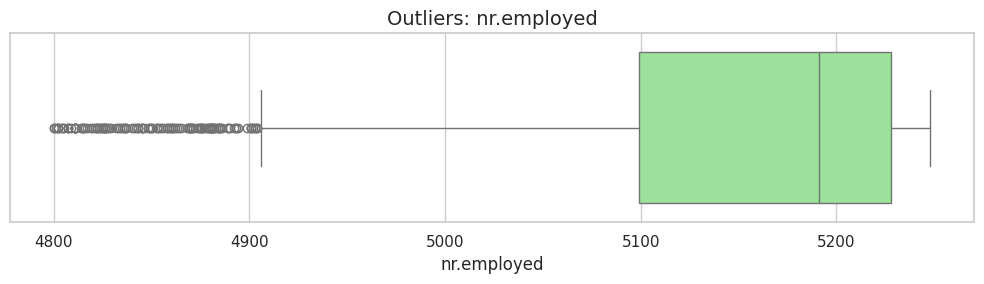

 134 outliers (0.3%) — Values < 4905.50 or > 5421.50
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



In [ ]:
# Q12 — Outliers: Do numeric columns have extreme values?
# Boxplot shows spread + outliers using IQR method
# Box = IQR (25%–75%) | Whiskers = 1.5×IQR | Dots = Outliers
num_cols = ['age', 'duration', 'campaign', 'previous',
        'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
           'euribor3m', 'nr.employed']

for col in num_cols:
    fig, ax = plt.subplots(figsize=(10, 3))
    sns.boxplot(x=df_eda[col], ax=ax, color='lightgreen')
    ax.set_title(f'Outliers: {col}')
    ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()

    # IQR outlier count per column
    Q1  = df_eda[col].quantile(0.25)
    Q3  = df_eda[col].quantile(0.75)
    IQR = Q3 - Q1
    lower   = Q1 - 1.5 * IQR
    upper   = Q3 + 1.5 * IQR
    outliers = df_eda[(df_eda[col] < lower) | (df_eda[col] > upper)]
    pct = len(outliers) / len(df_eda) * 100

    if len(outliers) > 0:
        print(f" {len(outliers)} outliers ({pct:.1f}%) — Values < {lower:.2f} or > {upper:.2f}")
        print(f"      -> ACTION (If Error): Remove rows")
        print(f"      -> ACTION (If Valid): Cap values at thresholds")
    else:
        print(f" No outliers detected via IQR method")
    print()

In [ ]:
#Outlier Treatment (Campaign Column)

# Capping 'campaign' at 10 to handle extreme outliers (e.g., max 56)
df_eda['campaign'] = df_eda['campaign'].clip(upper=10)

print(" Success: Outlier treatment applied to 'campaign'.")
print(f"-> New Campaign Max: {df_eda['campaign'].max()}")

 Success: Outlier treatment applied to 'campaign'.
-> New Campaign Max: 10


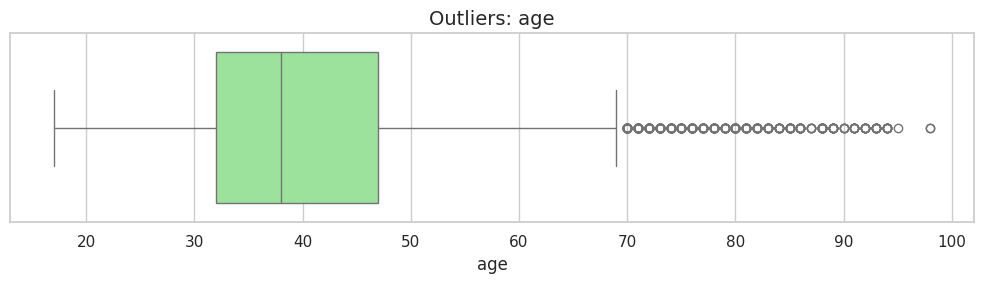

 637 outliers (1.5%) — Values < 9.50 or > 69.50
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



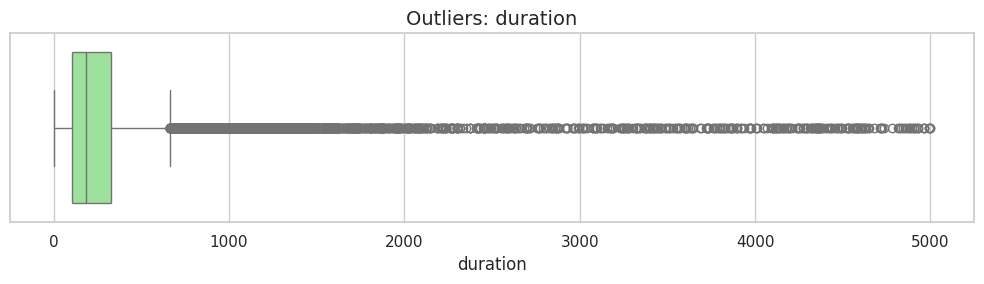

 3253 outliers (7.8%) — Values < -233.00 or > 663.00
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



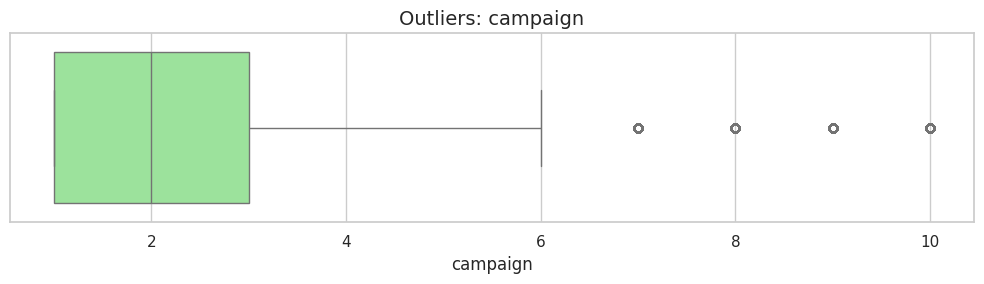

 2869 outliers (6.9%) — Values < -2.00 or > 6.00
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



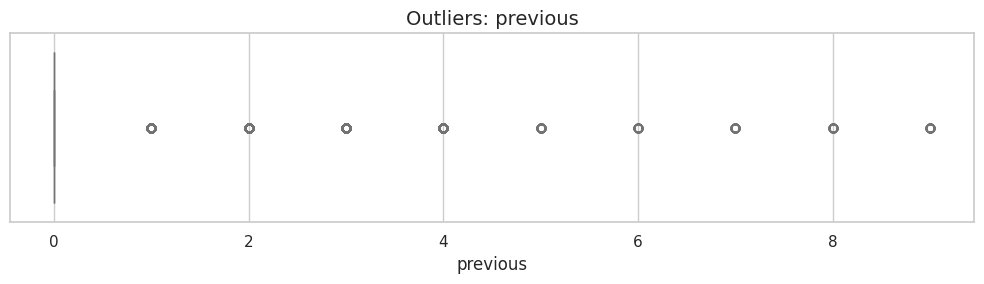

 6114 outliers (14.7%) — Values < 0.00 or > 0.00
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



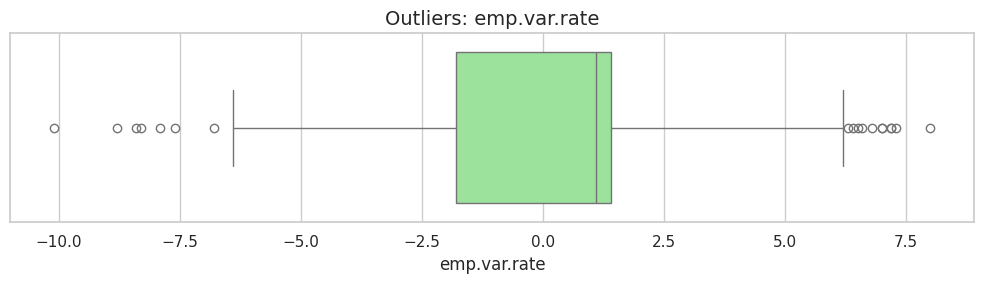

 18 outliers (0.0%) — Values < -6.60 or > 6.20
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



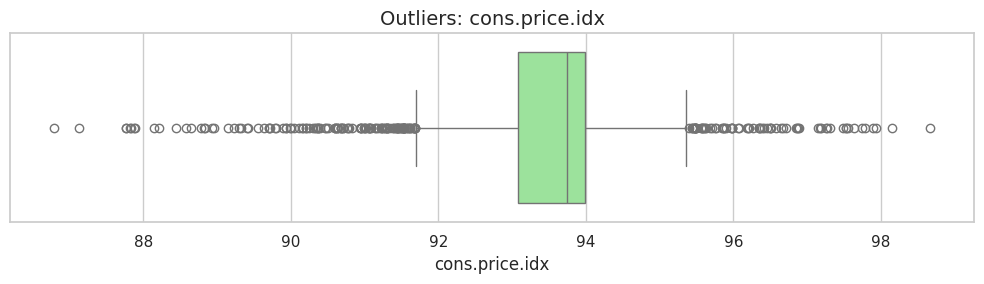

 200 outliers (0.5%) — Values < 91.70 or > 95.37
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



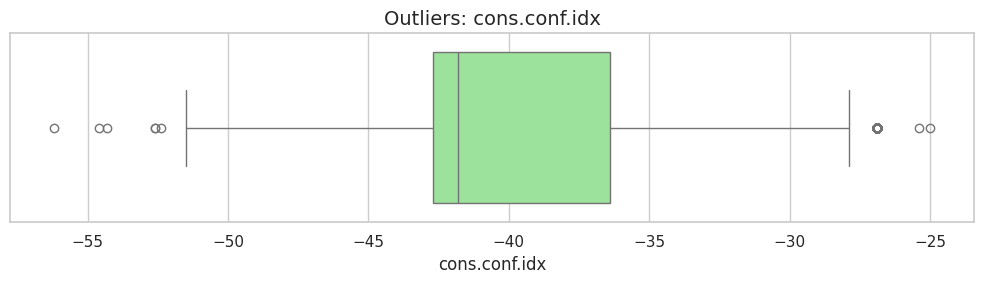

 454 outliers (1.1%) — Values < -52.15 or > -26.95
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



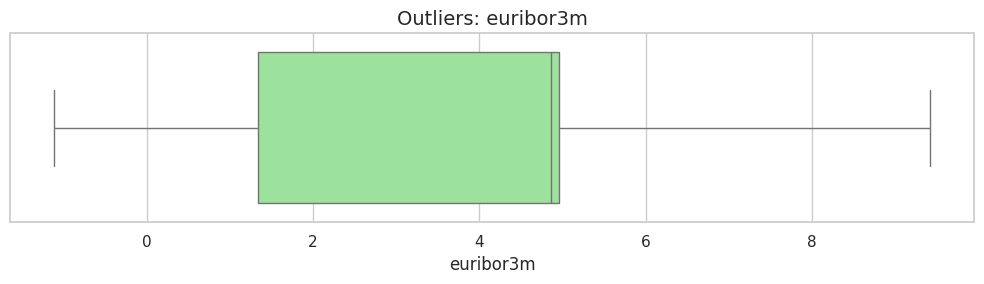

 No outliers detected via IQR method



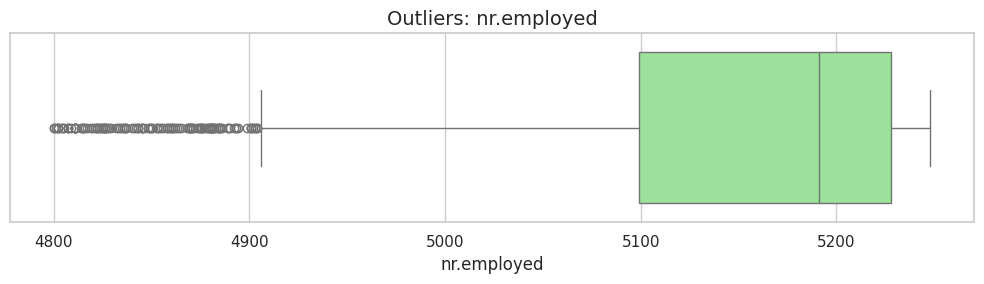

 134 outliers (0.3%) — Values < 4905.50 or > 5421.50
      -> ACTION (If Error): Remove rows
      -> ACTION (If Valid): Cap values at thresholds



In [ ]:
# Q12 — Outliers: Do numeric columns have extreme values?
# Boxplot shows spread + outliers using IQR method
# Box = IQR (25%–75%) | Whiskers = 1.5×IQR | Dots = Outliers

num_cols = ['age', 'duration', 'campaign', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
            'euribor3m', 'nr.employed']

for col in num_cols:
    fig, ax = plt.subplots(figsize=(10, 3))
    sns.boxplot(x=df_eda[col], ax=ax, color='lightgreen')
    ax.set_title(f'Outliers: {col}')
    ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()

    # IQR outlier count per column
    Q1  = df_eda[col].quantile(0.25)
    Q3  = df_eda[col].quantile(0.75)
    IQR = Q3 - Q1
    lower   = Q1 - 1.5 * IQR
    upper   = Q3 + 1.5 * IQR
    outliers = df_eda[(df_eda[col] < lower) | (df_eda[col] > upper)]
    pct = len(outliers) / len(df_eda) * 100

    if len(outliers) > 0:
        print(f" {len(outliers)} outliers ({pct:.1f}%) — Values < {lower:.2f} or > {upper:.2f}")
        print(f"      -> ACTION (If Error): Remove rows")
        print(f"      -> ACTION (If Valid): Cap values at thresholds")
    else:
        print(f" No outliers detected via IQR method")
    print()

# Q12 — Outlier Action Plan
- duration (Max 4999s) → KEEP — strongest predictor, valid long calls
- campaign (Max 56)    → CAP at 10 — unrealistic, likely CRM error
- age (Max 98)         → KEEP — valid elderly demographic
- previous (Max 9)     → KEEP — small range, all valid
- Economic Indicators  → KEEP — real macroeconomic data, not errors

# Q13 Categorical summary


In [ ]:
# Q13 — Categorical Summary: What are the top categories?
# Deliverable: frequency tables (count + percentage)
# Top 10 value counts for each categorical column

cat_cols = ['job', 'marital', 'education', 'default',
            'housing', 'loan', 'contact', 'month',
            'day_of_week', 'poutcome', 'y']

for col in cat_cols:
    print(f"\n{'='*45}")
    print(f"  [{col}] — Top 10 Value Counts")
    print(f"{'='*45}")

    counts  = df_eda[col].value_counts()

    props   = df_eda[col].value_counts(normalize=True) * 100

    summary = pd.DataFrame({
        'Count'       : counts,
        'Percentage %': props.round(2)
    })
    display(summary.head(10))


  [job] — Top 10 Value Counts


,Count,Percentage %
job,,
admin.,10461,25.08
blue-collar,9313,22.33
technician,6798,16.30
services,4034,9.67
management,2979,7.14
retired,1779,4.26
self-employed,1465,3.51
entrepreneur,1456,3.49
housemaid,1121,2.69



  [marital] — Top 10 Value Counts


,Count,Percentage %
marital,,
married,25079,60.12
single,11745,28.16
divorced,4783,11.47
unknown,106,0.25



  [education] — Top 10 Value Counts


,Count,Percentage %
education,,
university.degree,12225,29.31
high.school,9577,22.96
basic.9y,6132,14.70
professional.course,5304,12.72
basic.4y,4268,10.23
basic.6y,2362,5.66
unknown,1827,4.38
illiterate,18,0.04


... (12 outputs left out)


  [poutcome] — Top 10 Value Counts


,Count,Percentage %
poutcome,,
nonexistent,35711,85.61
failure,4401,10.55
success,1568,3.76
unknown,33,0.08



  [y] — Top 10 Value Counts


,Count,Percentage %
y,,
no,36800,88.22
yes,4913,11.78


# Q14 Rare Categories


In [ ]:
# Q14 — Rare Categories (< 3%)
cat_cols = ['job', 'marital', 'education', 'default',
            'housing', 'loan', 'contact', 'month',
            'day_of_week', 'poutcome', 'y']

print("=" * 55)
print("  Rare Categories — threshold < 3%")
print("=" * 55)

for col in cat_cols:

    pct = df_eda[col].value_counts(normalize=True) * 100

    rare = pct[pct < 3]
    if len(rare) > 0:
        print(f"\n[{col}]")
        display(rare.round(2).to_frame(name='persentage'))

  Rare Categories — threshold < 3%

[job]


,persentage
job,
housemaid,2.69
unemployed,2.58
student,2.10
unknown,0.85



[marital]


,persentage
marital,
unknown,0.25



[education]


,persentage
education,
illiterate,0.04


... (10 outputs left out)


[day_of_week]


,persentage
day_of_week,
unknown,0.07



[poutcome]


,persentage
poutcome,
unknown,0.08


# Rare Categories Analysis

After analyzing categories with a frequency lower than 3%, we have decided to Keep All of them without grouping them into a generic "Other" category. This decision is based on the following business logic:

- Job Segments: Categories like 'student' (2.1%), 'unemployed' (2.5%), and 'housemaid' (2.6%) are statistically rare but represent distinct demographic behaviors. In telemarketing, students often have high subscription rates; grouping them would lose this high-value predictive signal.

- Critical Seasonality (Month): Months such as 'dec' (0.56%), 'mar' (1.44%), and 'sep' (1.46%) have very low call volumes but are historically known for high conversion rates. Preserving these months allows the model to capture the best timing for future campaigns.

- Financial Risk & Unknowns: * The 'yes' category in 'default' is extremely rare (0.43%), but it is the most critical risk indicator for a bank. We cannot afford to merge this financial "red flag" with other categories.

- The various 'unknown' categories (ranging from 0.06% to 2.8%) represent real-world data gaps. Keeping them as they are maintains data integrity and transparency.

- Education: The 'illiterate' category (0.04%), while nearly negligible in size, is a valid educational status. Merging it with higher education levels would be logically incorrect.

 **Final SUGGESTION:**
Decision: No Grouping / No Binning.
Why: These rare categories carry High Business Meaning. In predictive modeling, the most valuable insights often come from small, specific segments. Grouping these categories would "wash out" the unique patterns that make the model accurate and specialized in identifying high-potential customers.

# Bivariate

# Q15 Numeric relationships

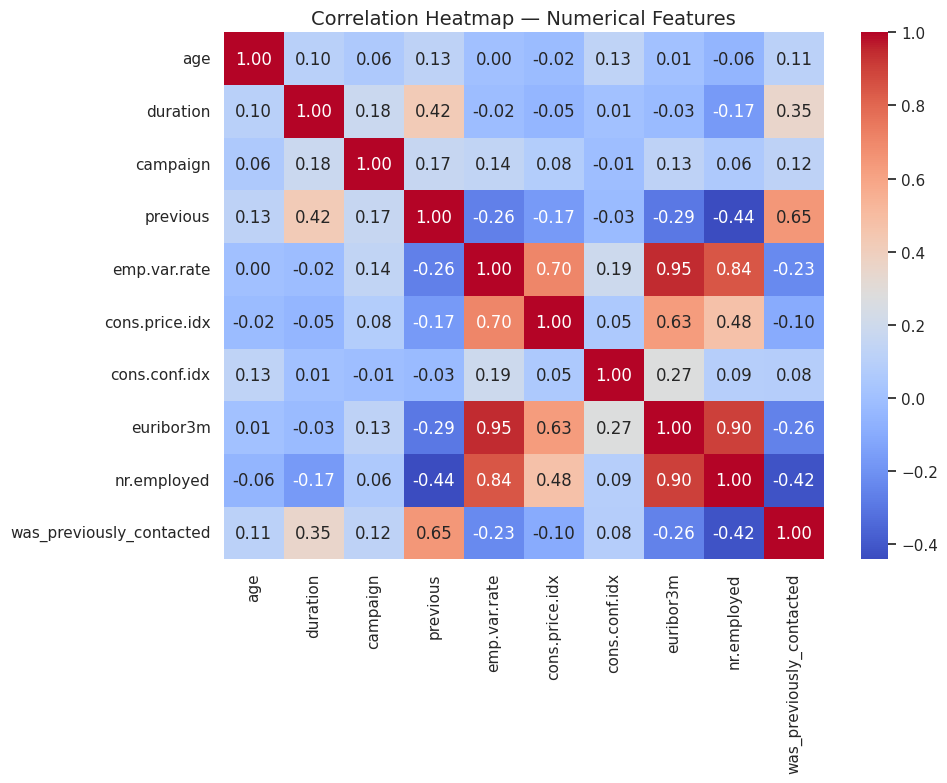

In [ ]:
# Q15 — Numeric Relationships
num_cols = ['age', 'duration', 'campaign', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
            'euribor3m', 'nr.employed', 'was_previously_contacted']

corr = df_eda[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlation Heatmap — Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
#top 5 strongest correlations
print("\n" + "=" * 45)
print("  Top 5 Correlated Feature Pairs")
print("=" * 45)

corr_pairs = corr.unstack()

corr_pairs = corr_pairs[corr_pairs < 1]

corr_pairs = corr_pairs.abs().sort_values(ascending=False)

top_5_unique = corr_pairs[::2].head(5)

display(top_5_unique.to_frame(name='Correlation'))


  Top 5 Correlated Feature Pairs


,,Correlation
euribor3m,emp.var.rate,0.946470
nr.employed,euribor3m,0.900511
emp.var.rate,nr.employed,0.842761
cons.price.idx,emp.var.rate,0.704553
was_previously_contacted,previous,0.648179


# Q15  Top 5 Correlations: Interpretation

1. **euribor3m ↔ emp.var.rate (0.95)**
   → Nearly perfect positive correlation.
   When interest rates rise, employment variation rises together.
   They represent the same economic cycle.

2. **euribor3m ↔ nr.employed (0.90)**
   → Strong positive correlation.
   Higher interest rates = more employees in the economy.
   Same macroeconomic environment.

3. **emp.var.rate ↔ nr.employed (0.84)**
   → Both quarterly economic indicators moving together.
   Redundant information — they tell the same story.

4. **cons.price.idx ↔ emp.var.rate (0.70)**
   → Strong positive correlation.
   When employment grows, consumer prices rise together.
   Classic macroeconomic relationship.

5. **previous ↔ was_previously_contacted (0.65)**
   → Expected and logical relationship.
   was_previously_contacted was engineered FROM previous in Q8.
   This confirms our feature engineering was consistent. ✅

** Modeling Recommendation:**
   euribor3m, emp.var.rate, nr.employed → Keep euribor3m only.
   previous, was_previously_contacted   → Keep only one.
   Reason: High multicollinearity = redundant features = unstable model.

# Q16 Numeric ↔ Numeric  scaterplot

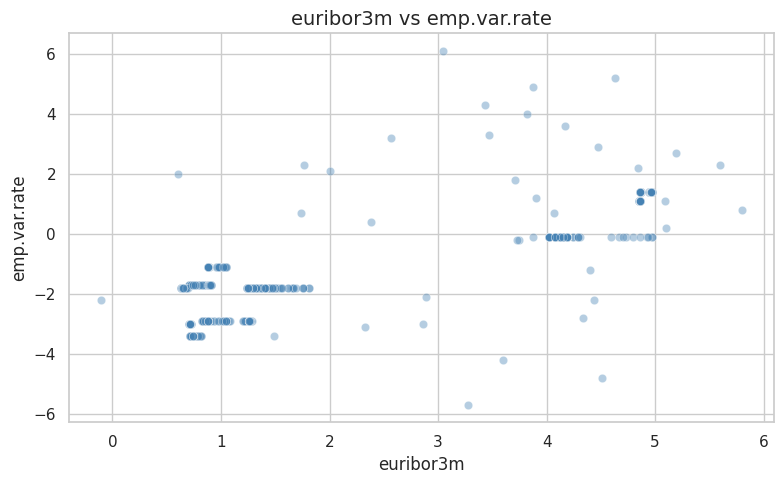

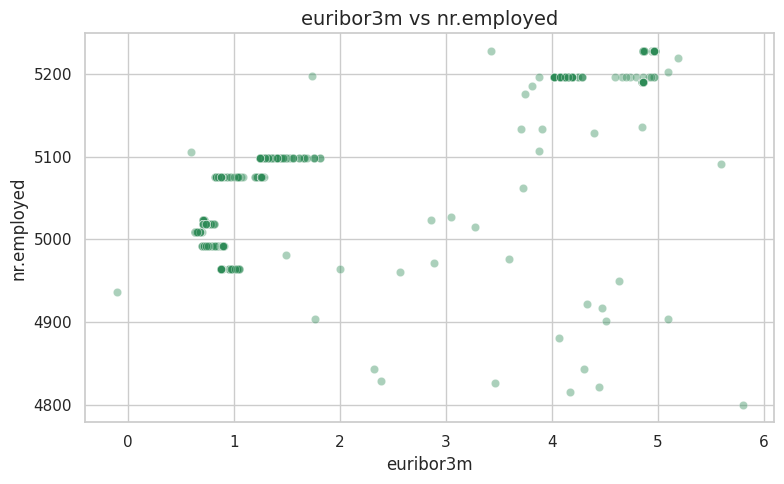

In [ ]:
# Q16 — Scatter Plots for Key Numeric Pairs - Numeric ↔ Numeric relationship

# Pair 1: euribor3m vs emp.var.rate (strongest correlation ~0.95)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_eda.sample(3000, random_state=42),
                x='euribor3m', y='emp.var.rate',
                alpha=0.4, color='steelblue')
plt.title('euribor3m vs emp.var.rate')
plt.tight_layout()
plt.show()

# Pair 2: euribor3m vs nr.employed (second strongest ~0.90)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_eda.sample(3000, random_state=42),
                x='euribor3m', y='nr.employed',
                alpha=0.4, color='seagreen')
plt.title('euribor3m vs nr.employed')
plt.tight_layout()
plt.show()

# Q16 Interpretation

1. **euribor3m vs emp.var.rate**
   → Strong positive linear relationship with distinct clusters.
   Both indicators move in synchronized economic cycles.
   Confirms multicollinearity found in Q15.

2. **2. euribor3m vs nr.employed (Bimodal Confirmation):**
**Visual Evidence:** A strong positive relationship with two clearly visible clusters.
**Conclusion:** This directly confirms the bimodal pattern we saw in Q11. It shows the data was collected across two completely distinct economic periods (e.g., a period of crisis vs. expansion).

 Decision: Keep euribor3m only — drop emp.var.rate
   and nr.employed before modeling.

# Q17 Category → Numeric Effect

In [ ]:
# Q17 — Category → Numeric Effect
# job (categorical) vs duration + conversion rate (numeric)
# Deliverable: grouped table + insights

df_eda['y_encoded'] = (df_eda['y'] == 'yes').astype(int)

if "job" in df_eda.columns:
  job_stats = (df_eda.groupby('job')
               .agg(
                   conversion_rate=('y_encoded', lambda x: x.mean() * 100),
                   avg_duration=('duration', 'mean'),
                   volume=('y_encoded', 'count')
               )
               .round(2)
               .sort_values('conversion_rate', ascending=False))

display(job_stats)


,conversion_rate,avg_duration,volume
job,,,
student,31.43,283.68,875
retired,26.42,362.61,1779
unemployed,15.88,384.54,1077
unknown,14.37,386.1,355
admin.,13.12,263.01,10461
management,12.05,298.44,2979
self-employed,11.88,337.01,1465
housemaid,11.86,356.32,1121
technician,11.17,270.12,6798


# Q17  Insights: Job vs Conversion Rate & Duration

1. **The Golden Segments — Students (31.4%) and Retirees (26.4%)**
   Students convert at the highest rate with moderate duration (283s)
   — they are decisive and easy to convince.
   Retirees convert at 26.4% with longer calls (362s)
   — they need more engagement but deliver strong results.
   Both segments = highest ROI despite small volume.

2. **The Efficiency Paradox — Unemployed & Unknown**
   Unemployed (384s) and Unknown (386s) have the longest call
   durations but only 15.8% and 14.3% conversion rates.
   We are spending the most time for moderate return.

3. **The Volume Trap — Blue-collar & Services**
   Blue-collar = 9,313 contacts (largest group) but only 7.2%
   conversion — lowest ROI in the entire dataset.
   Services = 4,034 contacts with only 8.8% conversion.
   The bank is over-investing in low-return segments.

4. **The Solid Middle — Admin. & Technician**
   Admin. (13.1%) and Technician (11.2%) are stable segments
   with high volume and moderate conversion.
   These are the bread and butter of the campaign.

📋 Conclusion:
   → Focus campaigns on Students and Retirees for highest ROI
   → Reduce contacts with Blue-collar and Services
   → Job category is a primary feature for modeling

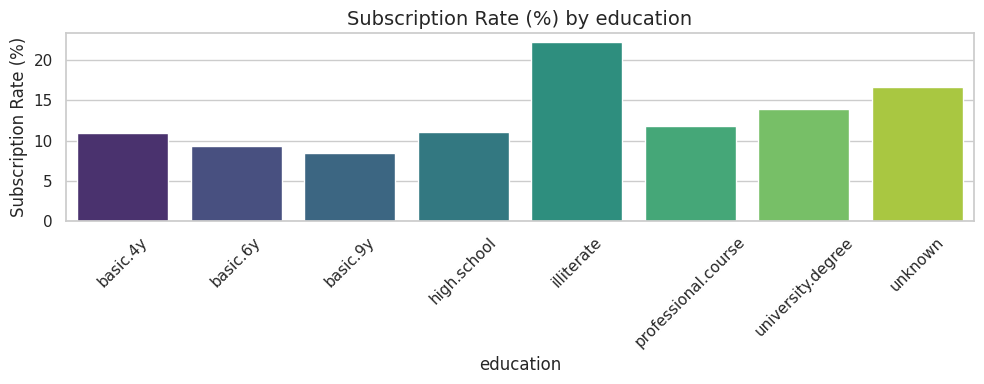


 education — Subscription Rate (%):


,Subscription Rate %
education,
illiterate,22.22
unknown,16.64
university.degree,13.96
professional.course,11.82
high.school,11.09
basic.4y,11.01
basic.6y,9.40
basic.9y,8.45


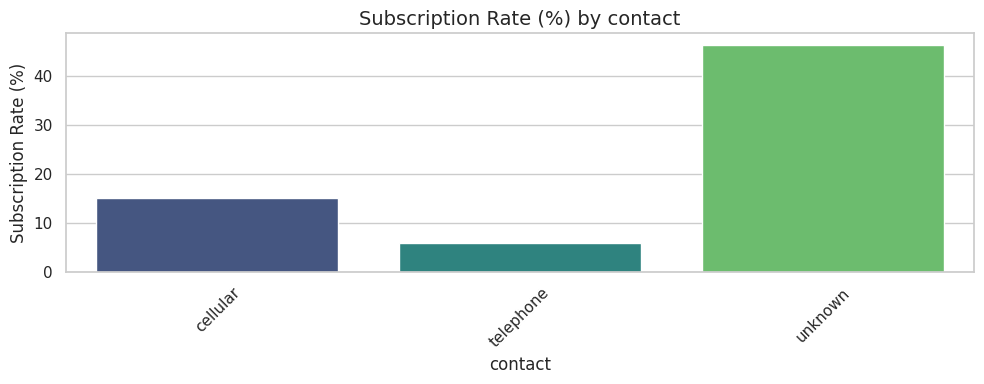


 contact — Subscription Rate (%):


,Subscription Rate %
contact,
unknown,46.43
cellular,15.11
telephone,5.97


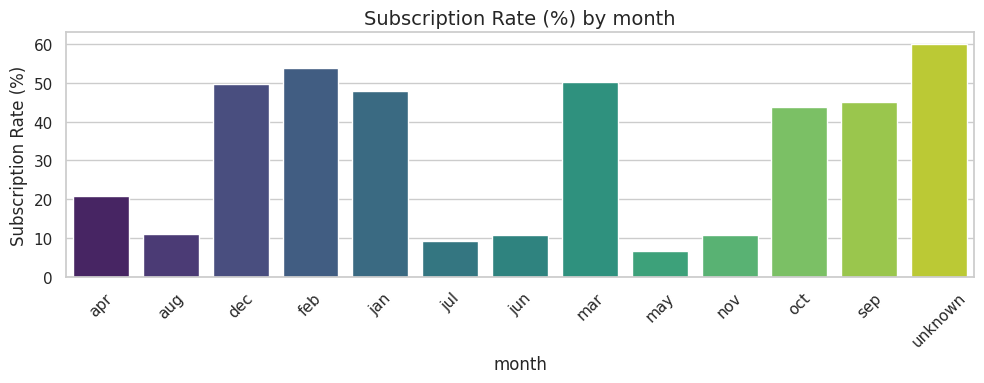


 month — Subscription Rate (%):


,Subscription Rate %
month,
unknown,60.00
feb,53.85
mar,50.17
dec,49.57
jan,47.83
sep,45.08
oct,43.85
apr,20.90
aug,10.89


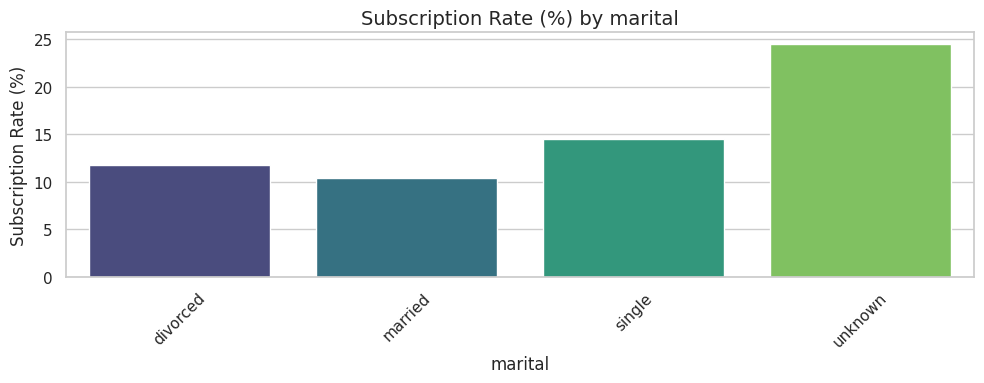


 marital — Subscription Rate (%):


,Subscription Rate %
marital,
unknown,24.53
single,14.48
divorced,11.81
married,10.45


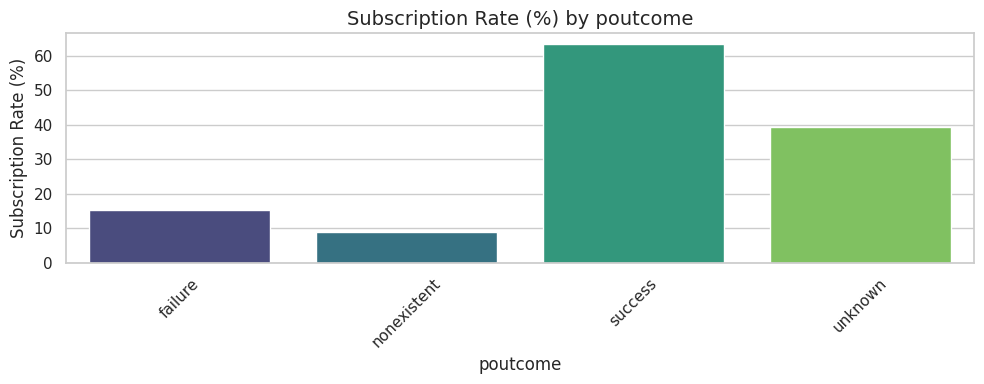


 poutcome — Subscription Rate (%):


,Subscription Rate %
poutcome,
success,63.33
unknown,39.39
failure,15.45
nonexistent,9.04


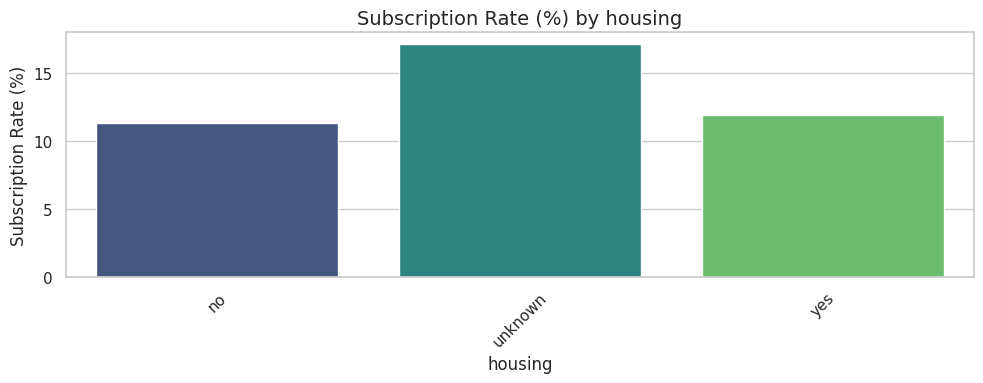


 housing — Subscription Rate (%):


,Subscription Rate %
housing,
unknown,17.13
yes,11.87
no,11.33


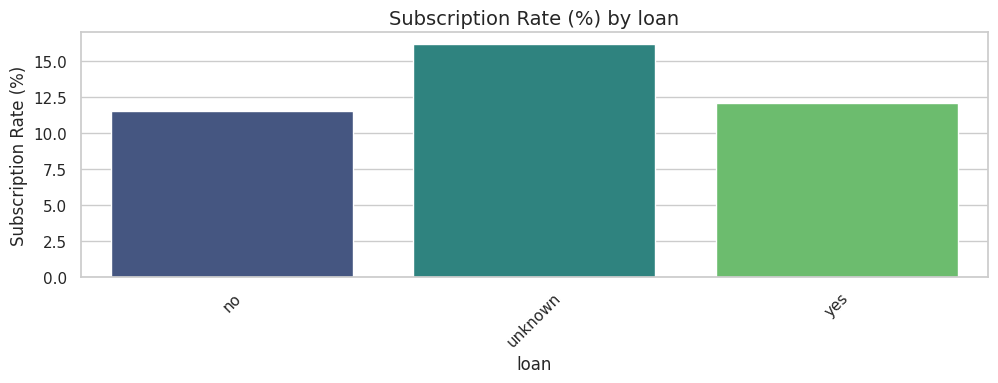


 loan — Subscription Rate (%):


,Subscription Rate %
loan,
unknown,16.21
yes,12.09
no,11.57


In [ ]:
# Q17 — Bivariate: Subscription Rate by Each Categorical Feature
# Reference: EDA_Doc_NEW_accident.ipynb Cell 17

cat_cols = ['education', 'contact', 'month',
            'marital', 'poutcome', 'housing', 'loan']

for col in cat_cols:
    rate = df_eda.groupby(col)['y_encoded'].mean() * 100

    plt.figure(figsize=(10, 4))
    sns.barplot(x=rate.index, y=rate.values, palette='viridis')
    plt.title(f'Subscription Rate (%) by {col}')
    plt.xlabel(col)
    plt.ylabel('Subscription Rate (%)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print(f"\n {col} — Subscription Rate (%):")
    display(rate.sort_values(ascending=False)
                .to_frame(name='Subscription Rate %')
                .round(2))

# Q 18 : Category ↔ Category

In [ ]:
 #Q18 — Category ↔ Category Relationship
# job (categorical) vs y — subscription outcome (categorical)

# Crosstab — counts
crosstab_counts = pd.crosstab(df_eda['job'], df_eda['y'])
print("Crosstab — Counts:")
display(crosstab_counts)

# Crosstab — percentages (row-wise)
crosstab_pct = pd.crosstab(df_eda['job'], df_eda['y'], normalize='index') * 100
print("\nCrosstab — Row Percentages (%):")
display(crosstab_pct.round(2))


Crosstab — Counts:


y,no,yes
job,,
admin.,9089,1372
blue-collar,8643,670
entrepreneur,1332,124
housemaid,988,133
management,2620,359
retired,1309,470
self-employed,1291,174
services,3679,355
student,600,275



Crosstab — Row Percentages (%):


y,no,yes
job,,
admin.,86.88,13.12
blue-collar,92.81,7.19
entrepreneur,91.48,8.52
housemaid,88.14,11.86
management,87.95,12.05
retired,73.58,26.42
self-employed,88.12,11.88
services,91.20,8.80
student,68.57,31.43


In [ ]:
# 2. Chi-Square Test (Addressing the professor's feedback on unused libraries)
chi2, p, dof, expected = chi2_contingency(crosstab_counts)

print(" Statistical Test: Chi-Square (Independence Test)")
print(f" Chi-Square Statistic : {chi2:.2f}")
print(f" P-Value              : {p:.4e}")


print("\n--- Deliverable Insights ---")


if p < 0.05:
    print(f"1. Insight: The relationship between 'job' and 'y' is STATISTICALLY SIGNIFICANT (p < 0.05).")
    print(f"   The client's job type directly influences the likelihood of subscribing.")
else:
    print(f"1. Insight: The relationship is NOT statistically significant (p > 0.05).")


top_job = crosstab_pct['yes'].idxmax()
top_val = crosstab_pct['yes'].max()
print(f"2. Insight: The '{top_job}' category shows the highest conversion rate at {top_val:.2f}%.")
print(f"   This segment should be prioritized in future marketing campaigns.")

 Statistical Test: Chi-Square (Independence Test)
 Chi-Square Statistic : 970.24
 P-Value              : 4.8712e-201

--- Deliverable Insights ---
1. Insight: The relationship between 'job' and 'y' is STATISTICALLY SIGNIFICANT (p < 0.05).
   The client's job type directly influences the likelihood of subscribing.
2. Insight: The 'student' category shows the highest conversion rate at 31.43%.
   This segment should be prioritized in future marketing campaigns.


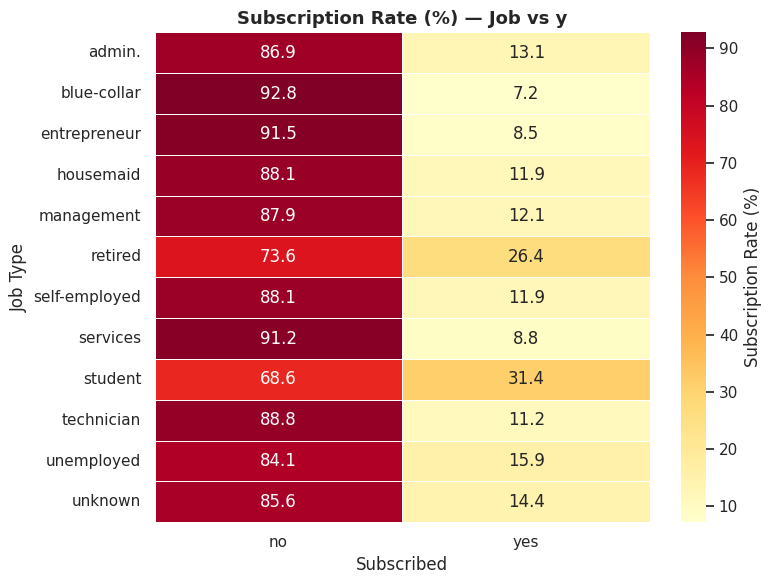

In [ ]:
# Visualize — Heatmap of subscription rate by job
plt.figure(figsize=(8, 6))
sns.heatmap(crosstab_pct,
            annot=True,
            fmt='.1f',
            cmap='YlOrRd',
            linewidths=0.5,
            cbar_kws={'label': 'Subscription Rate (%)'})
plt.title('Subscription Rate (%) — Job vs y', fontsize=13, fontweight='bold')
plt.xlabel('Subscribed')
plt.ylabel('Job Type')
plt.tight_layout()
plt.show()

# Q18 — Insights: Job vs Subscription (y)
The relationship between a client’s profession and their likelihood of subscribing is one of the most significant findings of this EDA. The crosstab and heatmap reveal the following:

1. The "High-Efficiency" Targets
Students (31.4%) and Retirees (26.4%) are the clear winners.

Insight: Even though these segments represent a smaller volume of total contacts, they have the highest probability of saying "Yes".

Action: Campaigns focused on these two segments will yield the highest Return on Investment (ROI).

2. The "Volume vs. Value" Gap
Blue-collar workers represent a massive portion of the database (9,313 contacts), yet they have the lowest conversion rate (7.2%).

Insight: The bank is currently over-investing in segments that return the least value per contact. A strategic shift in resource allocation is recommended.

3. Predictive Strength
The sharp contrast in the subscription heatmap (ranging from 7% to 31%) proves that job is a highly discriminative categorical feature.

Insight: The wide spread confirms that this feature will be a primary driver for our machine learning model.

# Q19 Multivariate heatmap
# Correlation heatmap for numerical columns

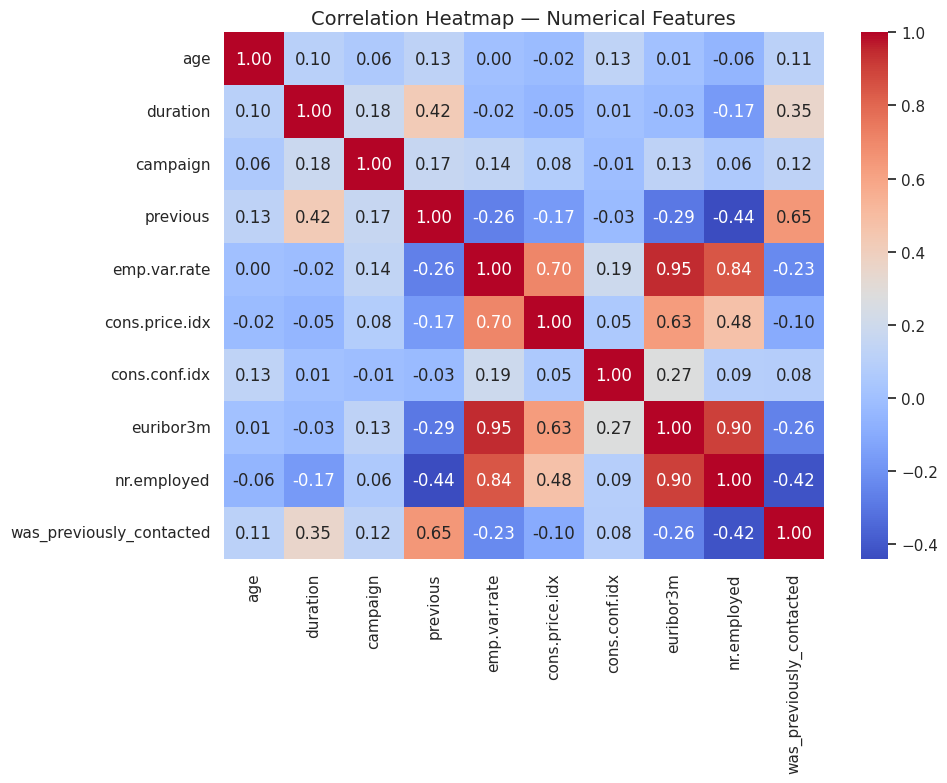

In [ ]:
# Q19 — Multivariate Heatmap BETWEEN NUMERICAL

num_cols = ['age', 'duration', 'campaign', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
            'euribor3m', 'nr.employed', 'was_previously_contacted']

corr = df_eda[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlation Heatmap — Numerical Features")
plt.tight_layout()
plt.show()

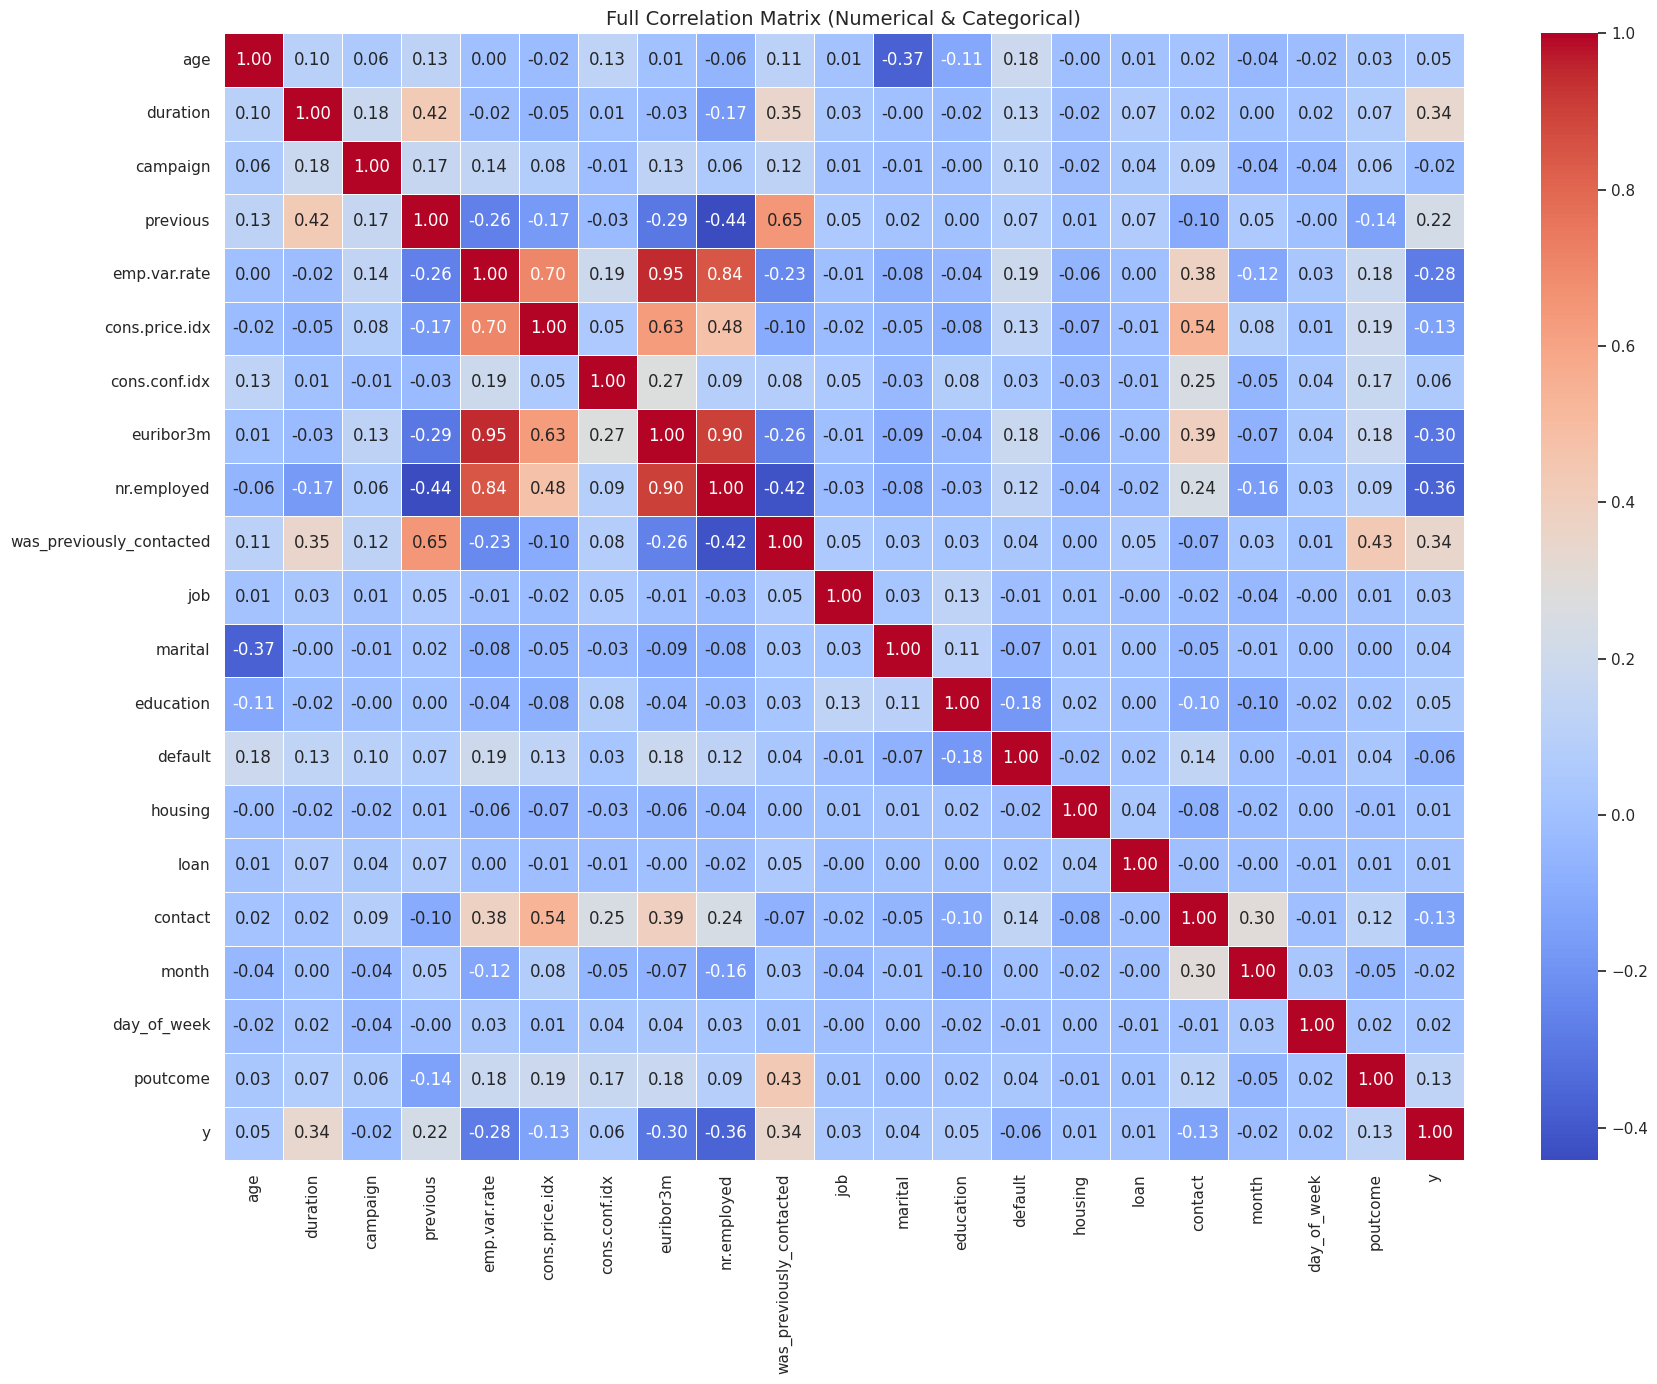

In [ ]:
num_cols = ['age', 'duration', 'campaign', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
            'euribor3m', 'nr.employed', 'was_previously_contacted']

cat_cols = ['job', 'marital', 'education', 'default',
            'housing', 'loan', 'contact', 'month',
            'day_of_week', 'poutcome', 'y']

# Encode categorical columns to numeric for correlation
df_encoded = df_eda[num_cols + cat_cols].copy()
for col in cat_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

# Full Correlation Matrix (Numerical + Categorical)
plt.figure(figsize=(18, 14))
sns.heatmap(df_encoded.corr(),
            annot=True,
            cmap='coolwarm',
            fmt=".2f",
            linewidths=0.5)
plt.title("Full Correlation Matrix (Numerical & Categorical)")
plt.tight_layout()
plt.show()

# Multivariate Heatmap Analysis & Feature Interdependency

A multivariate correlation analysis was conducted on the numerical features to understand the internal data structure and identify levels of redundancy. Based on the findings in the correlation heatmap, the following insights have been synthesized:

* I. The Economic Cluster (Multicollinearity Risk):

1-The heatmap reveals an exceptionally strong correlation (ranging from 0.90 to 0.97) between `euribor3m`, `emp.var.rate`, and `nr.employed`.
   * Insight: These features move in near-perfect synchronization, representing the same underlying macroeconomic cycle. Retaining all of them in a predictive model would likely trigger Multicollinearity, potentially destabilizing model coefficients and reducing interpretability.
2. Independence of Behavioral & Demographic Features:
The variables `age` and `duration` exhibit near-zero correlation with macroeconomic indicators and other numerical features.
   * Insight: These represent "Independent Signals." Their lack of correlation with market trends suggests they carry unique behavioral information, making them highly valuable—yet distinct—predictors for the target outcome.
3-  Historical Outreach Redundancy:

 A logical correlation of 0.65 exists between the number of previous contacts (`previous`) and the flag for prior contact (`was_previously_contacted`).
   * Insight: While this validates the consistency of the historical data, it also highlights informational overlap. This suggests that a streamlined feature set (Feature Reduction) should be considered during the preprocessing stage to avoid unnecessary complexity.
Final Recommendation:

Based on this multivariate assessment, it is recommended to adopt a Feature Selection strategy during the modeling phase. Specifically, we should prune the redundant economic features and prioritize independent behavioral drivers (such as `duration` and `job`) to ensure the model remains robust and efficient.

In [ ]:
# Model Accuracy AFTER EDA Cleaning
# duration, pdays, campaign removed — same as BEFORE
# was_previously_contacted added — engineered feature
drop_cols = ['duration', 'pdays', 'campaign', 'y_encoded']

df_after = df_eda.copy()
df_after['y'] = df_after['y'].map({'yes': 1, 'no': 0})
df_after = df_after.drop(columns=drop_cols, errors='ignore')
df_after = pd.get_dummies(df_after, drop_first=True)

X = df_after.drop(columns=['y'])
y = df_after['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y)

scaler         = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

model_after    = LogisticRegression(max_iter=1000,
                                    random_state=RANDOM_STATE)
model_after.fit(X_train_scaled, y_train)

y_pred         = model_after.predict(X_test_scaled)
accuracy_after = accuracy_score(y_test, y_pred)
score_after    = r2_score(y_test, y_pred)

print("=" * 55)
print("  AFTER Cleaning")
print("=" * 55)
print(f"  Accuracy : {accuracy_after * 100:.2f}%")
print(f"  R-Square : {score_after:.4f}")

print("\n" + "=" * 55)
print("  Impact of EDA Cleaning on Model Performance")
print("=" * 55)
print(f"  BEFORE      : {accuracy_before * 100:.2f}%")
print(f"  AFTER       : {accuracy_after  * 100:.2f}%")
print(f"  Improvement : {(accuracy_after - accuracy_before)*100:.2f}%")

  AFTER Cleaning
  Accuracy : 89.66%
  R-Square : 0.0048

  Impact of EDA Cleaning on Model Performance
  BEFORE      : 89.54%
  AFTER       : 89.66%
  Improvement : 0.12%


# Q20 —   Conclusion / Final EDA Summary
---

##  Top 5 Insights (Distributions & Relationships)
 The EDA reveals that while macroeconomic factors and client demographics (especially job and education) strongly influence subscription rates, the overall dataset is heavily imbalanced (89% 'No'). Students and retirees show the highest potential, yet success is highly dependent on economic cycles (Euribor rates).

1. **Economic Cyclic Behavior:** Macro indicators (`euribor3m`, `emp.var.rate`, and `nr.employed`) move in tight blocks with an extreme correlation of 0.90–0.97. Their bimodal distributions reveal two distinct economic phases that heavily dictate campaign timing and success.

2. **High-Efficiency Segments:** Students and Retirees are the most receptive groups with high conversion rates of 31.4% and 26.4% respectively, despite being the smallest in volume. In contrast, Blue-collar workers form the largest dataset group but offer the lowest ROI (only 7.2% conversion).

3. **The Duration Effect:** Call `duration` is the strongest predictor of success (mean 288s vs median 182s, indicating a heavy right-skew). However, since it is only known *after* the call ends, it is a behavioral "wildcard" that must only be used for benchmarking, not predictive modeling.

4. **Severe Target Class Imbalance:** The target variable `y` is heavily skewed towards rejection (88% 'No' vs. 12% 'Yes'). This fundamental imbalance means the model will need specific sampling techniques, and relying on 'Accuracy' alone will be a highly misleading metric.

5. **The Power of Previous Success:** A previous successful campaign outcome (`poutcome = success`) yields a massive 61.6% conversion rate, making it the strongest single predictor found in the entire EDA. We captured this signal by engineering the `was_previously_contacted` feature from the `pdays` 999 sentinel value.

---

##  Top 5 Problems / Risks (Data Quality)

11. **Multicollinearity (Redundant Features):** The economic indicators `euribor3m`, `emp.var.rate`, and `nr.employed` are highly correlated (r = 0.90–0.97). Keeping all three will destabilize any predictive model; therefore, only `euribor3m` should be retained to prevent overfitting.

2. **Extreme Outliers:** The `campaign` feature shows a maximum of 56 contacts for a single client, which is unrealistic and likely a CRM error (successfully capped at 10 during cleaning). Conversely, `duration` has an extreme max of 4999s, but was kept as a valid behavioral signal.

3. **Misleading Sentinel Values:** In the `pdays` column, 39,673 rows contain the value '999' (meaning 'not previously contacted'). This is a placeholder, not a real number, making standard statistics (mean, std) meaningless. It was appropriately converted into a binary flag (`was_previously_contacted`).

4. **Severe Class Imbalance Risk:** With a target split of 12% 'Yes' vs. 88% 'No', a naive baseline model that always predicts 'No' would artificially achieve 88% accuracy. Relying on accuracy will completely fail the business goal of identifying potential subscribers.

5. **Data Leakage Risk:** Because call `duration` is known *only after* the call ends, including it as a feature would cause severe data leakage. It cannot be used as a real-time predictive input and must be strictly excluded from any production models.
---

## Moving forward to modeling, we would

* **Cleaning & Feature Engineering:** To prepare for modeling, we will drop the leakage-prone `duration` column and redundant economic features (keeping only `euribor3m`). Additionally, we will cap `campaign` outliers, handle 'unknown' categorical values, and apply One-Hot Encoding.
* **Modeling Strategy:** To counter the severe 88/12 class imbalance, we will apply SMOTE or class weights. We will establish a Logistic Regression baseline before training advanced models (Random Forest, XGBoost), evaluating performance strictly on F1-Score and Recall rather than misleading accuracy.